# Coding-task bench with a baseline pilot: the CPU steps of `method.py`, re-run

This notebook re-runs the pipeline of the experiment *"Coding-task bench with a baseline pilot"* (iteration 2). The experiment builds a frozen **confirmation bench** for a study of *which algorithm an LLM chooses* when it writes code. **No ban prompt is rendered anywhere in it**: the bench only measures what the model does by default and what it can do when told.

**The bench.** There are thirteen LeetCode-derived tasks, for example k-th smallest, substring search, two-sum, connected components and topological order. Each task has a catalogue of 3-6 algorithm *modes*, 54 in all. For each task the bench holds:
- a frozen spec, with no complexity hints;
- hidden tests with an order-free checker, and one verified reference program per mode;
- gated labellers: a runtime tracer first, a static AST labeller second, and a blind LLM judge only when the two disagree;
- a **baseline pilot**: 50 programs from Qwen3-8B (FP8, T = 1.0, thinking off);
- **forced programs**: at least 40 per mode, from prompts such as *"Implement quickselect for this task."*

**Forced-ratio latent probability (FRLP).** For every mode this is an importance-sampling estimate of `log P(mode | baseline prompt)`. It uses forced programs scored under the baseline prompt and under the forcing prompts. FRLP shows how much probability the model keeps on algorithms it never samples by default.

**Ordering and freezing.** Three nominators answer "what would the model write instead of mode X?":
- the pilot frequency **ladder**;
- free-form **association** answers;
- canonical-token **proximity**.

Tasks are ordered by how much these nominators disagree. The first 12 gated tasks are then frozen with sha256 commitments.

### What runs here

`method.py` is a CLI with one sub-command per step. Two kinds of step cannot run on a CPU-only Colab:
- the GPU jobs: vLLM sampling and likelihood scoring with Qwen3-8B;
- the LLM-judge API calls.

Their stored outputs ship in `mini_demo_data.json`. Every CPU step is re-run with the original code, on the original files, and compared with the published numbers:

| # | `method.py` step | in this notebook |
|---|---|---|
| 1 | `specs` | **re-run**: spec freeze plus the `spec_v1` commitment hash |
| 2 | `gen` (GPU job A) | replayed: the stored pilot and forced samples |
| 3 | `build` | **re-run**: every reference in the original sandbox, against the frozen hidden tests |
| 4 | `label` | **re-run**: hidden tests and the frozen AST labeller on pilot programs. The runtime and judge labels are the stored ones |
| 5 | `order --stage A` | **re-run**: ladder, association and proximity nominations, and the task order |
| 6 | `gate` | **re-run** on the frozen, already-adjudicated gold sets (no API calls) |
| 7 | `gen --job C`, `score` (GPU jobs C and B) | replayed: the stored top-up attempts and log-likelihoods `l(program \| prompt)` |
| 8 | `frlp` | **re-run**: FRLP cells, sensitivities and validity |
| 9 | `order --stage B` | **re-run**, plus Kendall τ against Stage A |
| 10 | `freeze` | **re-run**: per-task sha256 commitments, checked against the original `bench/commitment.json` |
| 11 | `report` | **re-run**: pilot statistics, recount, no-ban audit and the commitment check |

Each step ends with a *re-run vs original* check. The last cells print the main results table and plot the pilot shares, the FRLP-implied mode probabilities and the FRLP cells.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, rapidfuzz — NOT on Colab, always install
_pip('loguru==0.7.3', 'rapidfuzz==3.14.6')

# numpy, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
# --- method.py import block (verbatim) ---
from __future__ import annotations

import argparse
import json
import sys
from pathlib import Path

from loguru import logger

# --- module-level imports of the bench/common modules used below
#     (stats, canon, commit, prompts, harness, order, gate, frlp, report) ---
import ast
import builtins
import hashlib
import io
import itertools
import keyword
import math
import os
import random
import re
import resource
import shutil
import statistics
import time
import tokenize
import types
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
from rapidfuzz.distance import Levenshtein

# --- notebook only ---
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-2/experiment-11/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["description"])
print(f"{len(data['examples'])} examples (one per bench task):", [ex["task"] for ex in data["examples"]])
print("curation:", *data["curation"], sep="\n  - ")
print("sampling:", data["sampling"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Coding-task bench with a baseline pilot (Qwen3-8B-FP8): one example per bench task with the frozen bench files, labelled pilot/forced samples, association answers, FRLP likelihood scores and the original results, for re-running the CPU steps of method.py.
13 examples (one per bench task): ['T03', 'T05', 'T06', 'T14', 'T10', 'T08', 'T04', 'T11', 'T13', 'R1', 'R2', 'R3', 'R6']
curation:
  - constant model/decoding fields dropped from sample rows (stored once under 'sampling')
  - program_scores restricted to the programs of the frozen FRLP sets (the only scores FRLP reads)
  - R6 tests.jsonl: 8 stress cases with 100,000-element arrays dropped (see bench_files_truncated)
sampling: {'model': 'Qwen/Qwen3-8B-FP8', 'decoding': {'temperature': 1.0, 'top_p': 1.0, 'top_k': -1, 'min_p': 0.0, 'repetition_penalty': 1.0, 'max_tokens': 1024, 'thinking': False}}


## Configuration

All tunable parameters live here. They are set to the **original run's values**: all 13 tasks, every hidden test case, all 50 pilot programs per task and 1,000 bootstrap draws. With them every CPU step reproduces the published numbers, and the whole notebook runs in about a minute on a 2-CPU machine (about 1 minute measured, installs included). For a quick smoke test, use the smallest values that still exercise every step: `N_TASKS = 1`, `N_TEST_CASES = 2`, `N_PILOT_PROGRAMS = 2`, `KAPPA_BOOT_REPS = HILL_REPS = 20` and `HILL_CI_REPS = HILL_CI_INNER_REPS = 10`.

Notes on what the parameters touch:
- `N_TASKS` keeps the first tasks of the catalogue's `TASK_ORDER`. Results that are defined over all 13 tasks (the `spec_v1` hash, the full task orders, Kendall τ) match the original only at `N_TASKS = 13`.
- `N_TEST_CASES` and `N_PILOT_PROGRAMS` only affect the sandbox re-runs (steps 3 and 4).
- The bootstrap counts only affect the confidence intervals.

In [5]:
# ---- demo scale (the comments give the original values) ----
N_TASKS = 13              # tasks processed, in the catalogue's TASK_ORDER; original: 13 (all)
N_TEST_CASES = None       # hidden test cases run per program in the sandbox (None = all); original: all (36-60 per task)
N_PILOT_PROGRAMS = 50     # pilot programs per task re-run through the tests + AST labeller; original: 50
WORKERS = 2               # sandbox worker threads (Colab has 2 CPUs); original: --workers 4 (build) / 5 (label)
KAPPA_BOOT_REPS = 1000    # bootstrap resamples of the gate's kappa CI; original: 1000
HILL_REPS = 1000          # rarefaction draws of Hill-1 at depth 25; original: 1000
HILL_CI_REPS = 300        # bootstrap resamples of the rarefied Hill-1 CI; original: 300
HILL_CI_INNER_REPS = 200  # rarefaction draws inside each of those resamples; original: 200

# ---- method.py CLI values used by the CPU steps ----
MAX_TASKS = 12                # freeze --max-tasks (the stop rule's 12-task cap); original: 12
MIN_GATED = min(6, N_TASKS)   # freeze refuses fewer gated tasks than this; original: 6

## `method.py` set-up and the shared `bench/common` helpers

`method.py` locates everything relative to its own folder (`ROOT`) and logs with loguru. Inside a notebook there is no `__file__`, so `ROOT` becomes `./demo_run`. The original folder layout is re-created there: `bench/<task_id>/`, `data/`, `results/`, `logs/` and `commitments.log`.

The cells after it define the small shared modules that every step uses. Each is copied verbatim from `bench/common/`:
- `catalogue.py`: the frozen task cards. Its literal constants come from the data file;
- `prompts.py`: the only three prompt builders of the bench;
- `commit.py`: the sha256 hash chain;
- `stats.py`: Wilson intervals, Hill numbers, Cohen's kappa, Kish ESS and log-sum-exp;
- `canon.py`: canonical token streams for proximity and coverage.

In [6]:
# method.py, module level (ROOT, logging)
ROOT = Path("demo_run").resolve()  # notebook: no __file__; the original layout is re-created here
sys.path.insert(0, str(ROOT))

(ROOT / "logs").mkdir(parents=True, exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")


def _file_sink(name: str) -> None:
    logger.add(ROOT / "logs" / f"{name}.log", rotation="30 MB", level="DEBUG")

In [7]:
# bench/common/catalogue.py — the frozen catalogue cards. Its literal constants are loaded from the demo data;
# the demo keeps the first N_TASKS tasks of TASK_ORDER (the hypothesis task order). The helpers are verbatim.
FORMAT_LINE = data["catalogue"]["FORMAT_LINE"]
FORCED_TEMPLATES = data["catalogue"]["FORCED_TEMPLATES"]
DESCRIPTIVE_FORCED_TEMPLATE = data["catalogue"]["DESCRIPTIVE_FORCED_TEMPLATE"]
ASSOCIATION_TEMPLATE = data["catalogue"]["ASSOCIATION_TEMPLATE"]
TASK_ORDER = data["catalogue"]["TASK_ORDER"][:N_TASKS]
TASKS = {t: data["catalogue"]["TASKS"][t] for t in TASK_ORDER}


def all_modes() -> list[tuple[str, str]]:
    """Global (task, mode) list in a fixed order; index = global mode_idx used in seeds."""
    out = []
    for t in TASK_ORDER:
        for m in TASKS[t]["modes"]:
            out.append((t, m))
    return out


def display_name(task: str, mode: str) -> str:
    return TASKS[task]["modes"][mode][0]


def mode_description(task: str, mode: str) -> str:
    return TASKS[task]["modes"][mode][1]


for t in TASK_ORDER:
    print(f"{t} {TASKS[t]['task_id']:<36} {TASKS[t]['signature']:<24} modes: {', '.join(TASKS[t]['modes'])}")

T03 T03_kth_smallest                     solve(nums, k)           modes: full_sort, size_k_heap, heapify_pop, quickselect, median_of_medians, counting_sort
T05 T05_two_sum                          solve(nums, target)      modes: hash_map, sort_two_pointers, brute_force, sort_binary_search
T06 T06_find_duplicate                   solve(nums)              modes: hash_set, sort_adjacent, floyd, value_binary_search, index_marking
T14 T14_top_k_frequent                   solve(nums, k)           modes: sort_by_count, heap, bucket_sort, quickselect_counts
T10 T10_connected_components             solve(n, edges)          modes: bfs, dfs, union_find, label_propagation
T08 T08_fibonacci                        solve(n)                 modes: iteration, memo_recursion, matrix_power, fast_doubling
T04 T04_substring_search                 solve(haystack, needle)  modes: naive, kmp, rabin_karp, z_algorithm, bmh, builtin
T11 T11_longest_increasing_subsequence   solve(nums)              modes: quadrat

In [8]:
# bench/common/prompts.py (verbatim)
def _cap(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def spec_text(task: str) -> str:
    return _cap(TASKS[task]["description"]) + "\n\n" + _cap(FORMAT_LINE)


def build_baseline(task: str) -> str:
    return spec_text(task)


def forced_segment(task: str, mode: str, k: int) -> str:
    if k == -1:  # descriptive variant (job C only, logged)
        d = mode_description(task, mode)
        d = d[0].upper() + d[1:]
        return _cap(DESCRIPTIVE_FORCED_TEMPLATE.format(d=d.rstrip(".") + "."))
    return _cap(FORCED_TEMPLATES[k].format(j=display_name(task, mode)))


def build_forced(task: str, mode: str, k: int) -> str:
    return forced_segment(task, mode, k) + "\n\n" + spec_text(task)


def build_association(task: str, mode: str) -> str:
    return _cap(TASKS[task]["description"]) + "\n\n" + _cap(ASSOCIATION_TEMPLATE.format(x=display_name(task, mode)))


def render_chat(tokenizer, user_text: str) -> str:
    """Qwen3 chat template, thinking disabled (adds the empty think block)."""
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": user_text}], tokenize=False, add_generation_prompt=True,
        enable_thinking=False)

In [9]:
# bench/common/commit.py (verbatim)
def canon_json(obj) -> str:
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False)


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def commit(log_path: Path, kind: str, payload_sha256: str, extra: dict | None = None) -> dict:
    lines = log_path.read_text().splitlines() if log_path.exists() else []
    prev = sha256_text(lines[-1]) if lines else "0" * 64
    rec = {"ts": time.strftime("%Y-%m-%dT%H:%M:%S%z"), "kind": kind, "sha256": payload_sha256,
           "prev_line_sha256": prev}
    if extra:
        rec.update(extra)
    with log_path.open("a") as f:
        f.write(canon_json(rec) + "\n")
    return rec


def verify_chain(log_path: Path) -> bool:
    lines = log_path.read_text().splitlines()
    prev = "0" * 64
    for line in lines:
        rec = json.loads(line)
        if rec["prev_line_sha256"] != prev:
            return False
        prev = sha256_text(line)
    return True

In [10]:
# bench/common/stats.py (verbatim; the two bootstrap defaults come from the config cell, original: 1000)
def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def hill1(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = Counter(labels)
    n = len(labels)
    return math.exp(-sum((v / n) * math.log(v / n) for v in c.values()))


def rarefied_hill1(labels: list[str], depth: int = 25, reps: int = HILL_REPS, seed: int = 0) -> float | None:
    if len(labels) < depth:
        return None
    rng = random.Random(seed)
    return float(np.mean([hill1(rng.sample(labels, depth)) for _ in range(reps)]))


def bootstrap_ci(labels: list[str], stat, reps: int = 1000, alpha: float = 0.10, seed: int = 0):
    if not labels:
        return (None, None)
    rng = random.Random(seed)
    vals = []
    for _ in range(reps):
        s = [labels[rng.randrange(len(labels))] for _ in range(len(labels))]
        v = stat(s)
        if v is not None and not (isinstance(v, float) and math.isnan(v)):
            vals.append(v)
    if not vals:
        return (None, None)
    return (float(np.quantile(vals, alpha / 2)), float(np.quantile(vals, 1 - alpha / 2)))


def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    if pe >= 1.0:
        return 1.0 if po == 1.0 else 0.0
    return (po - pe) / (1 - pe)


def pabak(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    k = max(len(set(a) | set(b)), 2)
    po = sum(x == y for x, y in zip(a, b)) / n
    return (k * po - 1) / (k - 1)


def raw_agreement(a, b):
    return sum(x == y for x, y in zip(a, b)) / len(a) if a else float("nan")


def kappa_bootstrap(a, b, reps: int = KAPPA_BOOT_REPS, alpha: float = 0.05, seed: int = 0):
    rng = random.Random(seed)
    n = len(a)
    vals = []
    for _ in range(reps):
        idx = [rng.randrange(n) for _ in range(n)]
        vals.append(cohen_kappa([a[i] for i in idx], [b[i] for i in idx]))
    vals = [v for v in vals if not math.isnan(v)]
    return (float(np.quantile(vals, alpha / 2)), float(np.quantile(vals, 1 - alpha / 2))) if vals else (None, None)


def logsumexp(x) -> float:
    x = np.asarray(x, dtype=float)
    if x.size == 0:
        return float("-inf")
    m = np.max(x)
    return float(m + np.log(np.sum(np.exp(x - m))))


def logmeanexp(x) -> float:
    return logsumexp(x) - math.log(len(x))


def kish_ess_log(w) -> float:
    w = np.asarray(w, dtype=float)
    return float(math.exp(2 * logsumexp(w) - logsumexp(2 * w)))


def kendall_tau(order_a: list[str], order_b: list[str]) -> float:
    pos_b = {t: i for i, t in enumerate(order_b)}
    items = [t for t in order_a if t in pos_b]
    n = len(items)
    conc = disc = 0
    for i in range(n):
        for j in range(i + 1, n):
            s = (pos_b[items[i]] - pos_b[items[j]])
            if s < 0:
                conc += 1
            elif s > 0:
                disc += 1
    return (conc - disc) / max(conc + disc, 1)


def self_test() -> dict:
    """Gate arithmetic check on a synthetic confusion matrix with a known answer.
    2x2 table [[20, 5], [10, 15]]: po = 0.70, pe = 0.5, kappa = 0.40, PABAK = 0.40."""
    a = ["x"] * 25 + ["y"] * 25
    b = ["x"] * 20 + ["y"] * 5 + ["x"] * 10 + ["y"] * 15
    k = cohen_kappa(a, b)
    pk = pabak(a, b)
    lo, hi = wilson(48, 50)
    return {"kappa": k, "kappa_ok": abs(k - 0.40) < 1e-9, "pabak": pk, "pabak_ok": abs(pk - 0.40) < 1e-9,
            "wilson_48_50": [lo, hi], "wilson_ok": abs(lo - 0.865) < 0.002 and abs(hi - 0.989) < 0.002,
            "hill1_uniform4": hill1(list("abcd")), "hill1_ok": abs(hill1(list("abcd")) - 4) < 1e-9,
            "ess_equal_weights": kish_ess_log([0.0] * 10), "ess_ok": abs(kish_ess_log([0.0] * 10) - 10) < 1e-9}

In [11]:
# bench/common/canon.py (verbatim)
_BUILTINS = set(dir(builtins))


def canon_tokens(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return []
    imported = set()
    doc_lines = set()
    for node in ast.walk(tree):
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            for a in node.names:
                imported.add((a.asname or a.name).split(".")[0])
            if isinstance(node, ast.ImportFrom) and node.module:
                imported.add(node.module.split(".")[0])
        if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and node.body:
            f = node.body[0]
            if isinstance(f, ast.Expr) and isinstance(f.value, ast.Constant) and isinstance(f.value.value, str):
                doc_lines.update(range(f.lineno, (f.end_lineno or f.lineno) + 1))
    out, names = [], {}
    prev = None
    try:
        toks = list(tokenize.generate_tokens(io.StringIO(code).readline))
    except (tokenize.TokenError, IndentationError, SyntaxError):
        return []
    for t in toks:
        if t.type in (tokenize.COMMENT, tokenize.NL, tokenize.ENCODING, tokenize.ENDMARKER):
            continue
        if t.type == tokenize.STRING and t.start[0] in doc_lines:
            continue
        if t.type == tokenize.NAME:
            s = t.string
            after_dot = prev is not None and prev.type == tokenize.OP and prev.string == "."
            if keyword.iskeyword(s) or s in _BUILTINS or s in imported or after_dot or s == "solve":
                out.append(s)
            else:
                if s not in names:
                    names[s] = f"v{len(names) + 1}"
                out.append(names[s])
        elif t.type == tokenize.NUMBER:
            out.append(t.string if t.string in ("0", "1") else "NUM")
        elif t.type == tokenize.STRING:
            out.append("STR")
        elif t.type == tokenize.NEWLINE:
            out.append("\\n")
        elif t.type == tokenize.INDENT:
            out.append("<IND>")
        elif t.type == tokenize.DEDENT:
            out.append("<DED>")
        else:
            out.append(t.string)
        if t.type not in (tokenize.NEWLINE, tokenize.INDENT, tokenize.DEDENT):
            prev = t
    # fold "- 1" literal -1 into a single token
    folded = []
    for tok in out:
        if tok == "1" and folded and folded[-1] == "-" and (len(folded) < 2 or folded[-2] in ("(", "[", ",", "=", "==", "return", "<", ">")):
            folded[-1] = "-1"
        else:
            folded.append(tok)
    return folded


def token_distance(a: list[str], b: list[str]) -> float:
    return Levenshtein.normalized_distance(a, b)


def shingles(tokens: list[str], k: int = 4) -> set:
    return {tuple(tokens[i:i + k]) for i in range(len(tokens) - k + 1)}


def jaccard(a: set, b: set) -> float:
    return len(a & b) / len(a | b) if (a or b) else 0.0

## Re-create the experiment folder from the demo data

Notebook-only glue. Each example of `mini_demo_data.json` holds one task's frozen bench files as verbatim text, and its sample, score and association rows. This cell writes them to the paths `method.py` uses, so the original functions below read and write exactly the files they read and wrote in the original run.

Three of these files are produced by steps this notebook cannot re-run:
- `data/samples_*.jsonl` (GPU job A, then labelling);
- `data/program_scores.jsonl` (GPU job B);
- `data/association.jsonl` (the association answers, already mapped to catalogue labels).

**Timeline.** The original run did not have all forced attempts from the start. GPU job A wrote 40 attempts per mode: rounds 0-7 of paraphrases 0-4. The Stage-A order and the gate were computed on that pool. Only afterwards did GPU job C add **top-ups**: rounds 8-11 for modes with fewer than 30 usable programs, and the descriptive variant (paraphrase id -1) for modes the model rarely obeyed. `data/samples_forced.jsonl` therefore starts with job A's attempts, and step 7 adds job C's attempts, as `gen --job C` and `label` did in the original run.

`REFS` (from `bench/common/refs.py`) maps each task and mode to its reference program.

In [12]:
EXAMPLES = {ex["task"]: ex for ex in data["examples"] if ex["task"] in TASK_ORDER}


def is_job_c(r: dict) -> bool:
    # forced top-ups of GPU job C: rounds 8-11 of paraphrases 0-4, and the descriptive variant (paraphrase id -1)
    return r["round"] >= 8 or r["paraphrase_id"] < 0


def materialize(root: Path) -> None:
    shutil.rmtree(root, ignore_errors=True)
    for sub in ("data", "results", "logs", "bench/common"):
        (root / sub).mkdir(parents=True, exist_ok=True)
    rows = {"samples_pilot.jsonl": [], "samples_forced.jsonl": [], "association.jsonl": [], "program_scores.jsonl": []}
    for t, ex in EXAMPLES.items():
        d = root / "bench" / ex["task_id"]
        for rel, text in ex["bench_files"].items():
            (d / rel).parent.mkdir(parents=True, exist_ok=True)
            (d / rel).write_text(text, encoding="utf-8")
        rows["samples_pilot.jsonl"] += [dict(r, **data["sampling"]) for r in ex["pilot_rows"]]
        rows["samples_forced.jsonl"] += [dict(r, **data["sampling"]) for r in ex["forced_rows"] if not is_job_c(r)]
        rows["association.jsonl"] += ex["association_rows"]
        rows["program_scores.jsonl"] += ex["program_scores"]
    for name, rs in rows.items():
        with (root / "data" / name).open("w") as f:
            for r in rs:
                f.write(json.dumps(r) + "\n")
    # the distinct prompts that were actually sent to the model (input of the no-ban audit in `report`)
    with (root / "logs" / "prompts_rendered.jsonl").open("w") as f:
        for t, ex in EXAMPLES.items():
            for p in ex["rendered_prompts"]:
                f.write(json.dumps({"sample_id": p["sample_id"], "condition": p["condition"], "task": t,
                                    "user_text": p["user_text"]}) + "\n")
    for name, rs in rows.items():
        print(f"  data/{name:<22} {len(rs):>6} rows")
    print(f"  ({sum(is_job_c(r) for ex in EXAMPLES.values() for r in ex['forced_rows'])} job-C top-up attempts "
          "are added to data/samples_forced.jsonl in step 7)")


materialize(ROOT)

# bench/common/refs.py: REFS[task][mode] = the verified reference program (same text as bench/<task>/references/<mode>.py)
REFS = {t: {m: ex["bench_files"][f"references/{m}.py"] for m in TASKS[t]["modes"]} for t, ex in EXAMPLES.items()}


# bench/common/testgen.py (verbatim)
def read_tests(path: Path) -> list[dict]:
    return [json.loads(l) for l in path.open()]


for t, ex in EXAMPLES.items():
    if ex["bench_files_truncated"]:
        print(f"  note: {t} tests.jsonl is shortened in the demo data:", ex["bench_files_truncated"]["tests.jsonl"]["reason"])

  data/samples_pilot.jsonl       650 rows
  data/samples_forced.jsonl     2160 rows
  data/association.jsonl        1080 rows
  data/program_scores.jsonl     9144 rows
  (420 job-C top-up attempts are added to data/samples_forced.jsonl in step 7)
  note: R6 tests.jsonl is shortened in the demo data: stress cases with 100,000-element arrays (5.7 MB) left out of the demo


## Step 1 — `specs`: freeze the task specs (commitment `spec_v1`)

Every prompt follows the same scaffold: `[condition segment] + blank line + DESCRIPTION + blank line + FORMAT`.

- The **baseline** prompt is the spec alone.
- A **forced** prompt prepends one of five fixed paraphrases. Templates 0-4 are used; 5-9 are frozen but never rendered.
- The **descriptive** variant prepends *"Implement the approach described as: <mechanism>"*. It was used only for modes the model rarely obeyed.
- The **association** prompt asks for *"the standard alternative to X"*.

`cmd_specs` writes `bench/<task_id>/spec.json` and appends the sha256 of all frozen specs to the hash chain `commitments.log`. With all 13 tasks, the hash must equal the original `spec_v1` commitment.

In [13]:
def cmd_specs(args: argparse.Namespace) -> None:
    frozen = {}
    for t in TASK_ORDER:
        c = TASKS[t]
        d = ROOT / "bench" / c["task_id"]
        d.mkdir(parents=True, exist_ok=True)
        spec = {"task": t, "task_id": c["task_id"], "leetcode_ids": c["leetcode_ids"], "signature": c["signature"],
                "description": c["description"], "format_line": FORMAT_LINE, "spec_text": spec_text(t),
                "bounds": c["bounds"],
                "catalogue": [{"mode": m, "display_name": v[0], "mechanism": v[1]} for m, v in c["modes"].items()],
                "aliases": c["aliases"], "forced_templates": FORCED_TEMPLATES,
                "descriptive_forced_template": DESCRIPTIVE_FORCED_TEMPLATE,
                "association_template": ASSOCIATION_TEMPLATE, "spec_version": 1}
        (d / "spec.json").write_text(json.dumps(spec, indent=1))
        frozen[t] = spec
    h = sha256_text(canon_json(frozen))
    rec = commit(ROOT / "commitments.log", "spec_v1", h, {"n_tasks": len(frozen)})
    logger.info(f"spec v1 frozen for {len(frozen)} tasks: {rec}")


cmd_specs(argparse.Namespace())

10:11:59|INFO   |spec v1 frozen for 13 tasks: {'ts': '2026-10-26T10:11:59+0000', 'kind': 'spec_v1', 'sha256': '87a6a7a34ce1cf7e25eafe35b36309fa92076c1fee28fced2e19fa9c4ae56223', 'prev_line_sha256': '0000000000000000000000000000000000000000000000000000000000000000', 'n_tasks': 13}


In [14]:
orig_spec = json.loads(data["original"]["commitments_log"][0])
new_spec = json.loads((ROOT / "commitments.log").read_text().splitlines()[0])
print(f"spec_v1 sha256, re-run  : {new_spec['sha256']}  ({new_spec['n_tasks']} tasks)")
print(f"spec_v1 sha256, original: {orig_spec['sha256']}  ({orig_spec['n_tasks']} tasks)")
print("hash matches the original commitment:", new_spec["sha256"] == orig_spec["sha256"],
      "" if N_TASKS == 13 else "(expected only with N_TASKS = 13)")
same = sum((ROOT / "bench" / ex["task_id"] / "spec.json").read_text(encoding="utf-8") == ex["bench_files"]["spec.json"]
           for ex in EXAMPLES.values())
print(f"re-written spec.json byte-identical to the frozen file: {same}/{len(EXAMPLES)} tasks")

t0 = TASK_ORDER[0]
m0, m1 = list(TASKS[t0]["modes"])[:2]
print(f"\n--- baseline prompt ({t0}) ---\n{build_baseline(t0)}")
print(f"\n--- forced prompt, template 0, mode {m1} (first line) ---\n{build_forced(t0, m1, 0).splitlines()[0]}")
print(f"\n--- descriptive forced variant, mode {m1} (first line) ---\n{build_forced(t0, m1, -1).splitlines()[0]}")
print(f"\n--- association prompt, X = {m0} (last line) ---\n{build_association(t0, m0).splitlines()[-1]}")

spec_v1 sha256, re-run  : 87a6a7a34ce1cf7e25eafe35b36309fa92076c1fee28fced2e19fa9c4ae56223  (13 tasks)
spec_v1 sha256, original: 87a6a7a34ce1cf7e25eafe35b36309fa92076c1fee28fced2e19fa9c4ae56223  (13 tasks)
hash matches the original commitment: True 


re-written spec.json byte-identical to the frozen file: 13/13 tasks

--- baseline prompt (T03) ---
Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

--- forced prompt, template 0, mode size_k_heap (first line) ---
Implement a size-k heap for this task.

--- descriptive forced variant, mode size_k_heap (first line) ---
Implement the approach described as: Keep a heap bounded by k elements while scanning (or heapq.nsmalles

## Step 2 — `gen` (GPU job A): sampling with vLLM. Replayed from storage

On the original machine (RTX 2000 Ada 16 GB) GPU job A sampled Qwen3-8B-FP8 with vLLM:
- 50 baseline pilot programs per task;
- 20 association answers per mode;
- 8 rounds × 5 forced paraphrases per mode, 2,160 forced attempts in all.

Job C's top-ups come later, in step 7.

The decoding settings were T = 1.0, top_p = 1, top_k = -1 and max 1,024 tokens, with thinking disabled through the Qwen3 chat template. The seeds were fixed: base 20261020 plus per-sample offsets.

`cmd_gen` is shown verbatim but **not called**. Its labelled outputs are the rows in `data/samples_pilot.jsonl` and `data/samples_forced.jsonl`.

In [15]:
# GPU job A / C / D (vLLM). Verbatim from method.py; NOT called here (needs a 16 GB GPU, vLLM and the model weights).
def cmd_gen(args: argparse.Namespace) -> None:
    _file_sink(f"gen_job_{args.job}")
    from bench.common import gen_vllm
    gen_vllm.set_cache_env(ROOT)
    if args.job == "A":
        paraphrases = [int(x) for x in args.paraphrases.split(",")]
        gen_vllm.job_a(ROOT, args.model, args.max_num_seqs, args.gpu_util, args.n_pilot, args.n_assoc,
                       args.forced_rounds, paraphrases)
    elif args.job == "C":
        gen_vllm.job_c(ROOT, args.model, args.max_num_seqs, args.gpu_util, Path(args.plan))
    elif args.job == "D":
        gen_vllm.job_d(ROOT, args.model, args.max_num_seqs, args.gpu_util, args.tasks.split(","), args.n_pilot)


pilot_rows = [json.loads(l) for l in (ROOT / "data" / "samples_pilot.jsonl").open()]
forced_rows = [json.loads(l) for l in (ROOT / "data" / "samples_forced.jsonl").open()]
for t in TASK_ORDER:
    pr = [r for r in pilot_rows if r["task"] == t]
    fr = [r for r in forced_rows if r["task"] == t]
    print(f"{t}: {len(pr)} pilot samples {dict(Counter(r['label'] for r in pr))}; {len(fr)} forced attempts (job A)")
ex_row = next(r for r in pilot_rows if r["task"] == TASK_ORDER[0])
print(f"\nexample pilot program {ex_row['sample_id']} (seed {ex_row['seed']}, label {ex_row['label']}, "
      f"passed {ex_row['passed']}):\n{ex_row['code']}")

T03: 50 pilot samples {'full_sort': 50}; 240 forced attempts (job A)
T05: 50 pilot samples {'hash_map': 50}; 160 forced attempts (job A)
T06: 50 pilot samples {'hash_set': 50}; 200 forced attempts (job A)
T14: 50 pilot samples {'sort_by_count': 50}; 160 forced attempts (job A)
T10: 50 pilot samples {'union_find': 50}; 160 forced attempts (job A)
T08: 50 pilot samples {'iteration': 50}; 160 forced attempts (job A)
T04: 50 pilot samples {'naive': 50}; 240 forced attempts (job A)
T11: 50 pilot samples {'quadratic_dp': 50}; 120 forced attempts (job A)
T13: 50 pilot samples {'sort_sweep': 50}; 120 forced attempts (job A)
R1: 50 pilot samples {'greedy_end': 50}; 160 forced attempts (job A)
R2: 50 pilot samples {'dfs_parent': 50}; 160 forced attempts (job A)
R3: 50 pilot samples {'kahn': 50}; 160 forced attempts (job A)
R6: 50 pilot samples {'binary_search': 49, 'other': 1}; 120 forced attempts (job A)

example pilot program T03:pilot:0 (seed 20261020, label full_sort, passed True):
def solve

## Step 3 — `build`: hidden tests, checkers and references in the sandbox

`method.py build` builds the hidden tests and checks the references:
- It makes the tests from LeetCodeDataset cases plus generated edge and stress cases: 684 cases, at most 45 parsed cases per task.
- It times the reference of every mode and sets per-case limits of `max(1 s, 10 × fastest reference)`.
- It requires every reference to pass at no more than 0.25 × the limit.
- It requires every mutant to fail.

The generator needs the dependency dataset, so the demo keeps the **frozen** `tests.jsonl`. It re-runs the reference part of `build_task`. Every reference must pass the hidden tests in the original sandbox, and each case's limit must follow from the reference times stored with it.

The sandbox is the original one. `harness.py` starts a fresh `python3.12 -I -S runner.py` subprocess per program, with RLIMIT_AS 2 GB. The runner blocks dangerous imports, runs every case in a thread with its time limit, and checks the output with the task's order-free checker.

In [16]:
# Verbatim from method.py; NOT called here: `extract` needs the dependency dataset and `build` regenerates the tests from it.
def cmd_extract(args: argparse.Namespace) -> None:
    _file_sink("extract")
    from bench.common.build import extract
    extract(ROOT)


def cmd_build(args: argparse.Namespace) -> None:
    _file_sink("build")
    from bench.common.build import build_task, exp_bruteforce_check, smoke_humanevalplus
    from bench.common.catalogue import TASK_ORDER
    tasks = args.tasks.split(",") if args.tasks else TASK_ORDER
    reps = {t: build_task(ROOT, t, workers=args.workers) for t in tasks}
    smoke = smoke_humanevalplus(ROOT)
    brute = exp_bruteforce_check(ROOT) if ("T11" in tasks and "T08" in tasks) else None
    out = ROOT / "results" / "build_summary.json"
    prev = json.loads(out.read_text()) if out.exists() else {"tasks": {}}
    prev["tasks"].update(reps)
    prev["humanevalplus_smoke"] = smoke
    if brute is not None:
        prev["exponential_bruteforce_check"] = brute
    out.write_text(json.dumps(prev, indent=1))
    logger.info(f"humanevalplus smoke: {smoke}; exponential brute force: {brute}")

In [17]:
%%writefile demo_run/bench/common/checkers.py
"""Order-free validity checkers, one per task (stdlib only; loaded by the sandbox runner by file path).

check(kwargs, expected, output) -> bool.  kwargs is a fresh copy of the case input.
"""


def _is_int(x):
    return isinstance(x, int) and not isinstance(x, bool)


def _pairs(x):
    try:
        return [[int(a), int(b)] for a, b in x]
    except (TypeError, ValueError):
        return None


def check_scalar_int(kwargs, expected, output):
    return _is_int(output) and output == expected


def check_two_sum(kwargs, expected, output):
    if not isinstance(output, (list, tuple)) or len(output) != 2 or not all(_is_int(v) for v in output):
        return False
    return sorted(output) == sorted(expected)


def check_merge(kwargs, expected, output):
    if not isinstance(output, (list, tuple)):
        return False
    p = _pairs(output)
    return p is not None and sorted(p) == expected


def check_topk(kwargs, expected, output):
    if not isinstance(output, (list, tuple)) or not all(_is_int(v) for v in output):
        return False
    return len(output) == len(expected) and sorted(output) == sorted(expected)


def check_bool(kwargs, expected, output):
    return isinstance(output, (bool, int)) and bool(output) == expected


def check_topo(kwargs, expected, output):
    if not isinstance(output, (list, tuple)):
        return False
    n = kwargs["n"]
    if expected == []:
        return len(output) == 0
    if len(output) != n or not all(_is_int(v) for v in output) or sorted(output) != list(range(n)):
        return False
    pos = {v: i for i, v in enumerate(output)}
    return all(pos[b] < pos[a] for a, b in kwargs["prerequisites"])


def check_first_last(kwargs, expected, output):
    return isinstance(output, (list, tuple)) and len(output) == 2 and all(_is_int(v) for v in output) and \
        list(output) == expected


CHECK = {
    "T03": check_scalar_int, "T04": check_scalar_int, "T05": check_two_sum, "T06": check_scalar_int,
    "T08": check_scalar_int, "T10": check_scalar_int, "T11": check_scalar_int, "T13": check_merge,
    "T14": check_topk, "R1": check_scalar_int, "R2": check_bool, "R3": check_topo, "R6": check_first_last,
}

Writing demo_run/bench/common/checkers.py


In [18]:
%%writefile demo_run/bench/common/runner.py
"""Sandbox runner (stdlib only).  Executed as: python3.12 -I -S runner.py < payload.json

payload: {"code", "task", "checkers_path", "cases": [{"kwargs_json", "expected_json", "limit"}]}
Prints one JSON line per case: {"i", "status": ok|wrong|error|timeout, "t", "msg"} and stops at the first timeout.
The candidate may not import os, subprocess, socket, shutil, ctypes or multiprocessing.
"""

import builtins
import importlib.util
import io
import json
import os
import sys
import threading
import time

FORBIDDEN = {"os", "subprocess", "socket", "shutil", "ctypes", "multiprocessing", "pty", "signal", "resource"}
CAND = "__candidate__"


def main():
    payload = json.loads(sys.stdin.read())
    sys.stdin = io.StringIO("")
    out = sys.stdout
    spec = importlib.util.spec_from_file_location("checkers", payload["checkers_path"])
    chk_mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(chk_mod)
    check = chk_mod.CHECK[payload["task"]]
    # pre-import common stdlib modules so their own internal imports are unaffected by the hook
    for m in ("heapq", "bisect", "collections", "functools", "itertools", "math", "random", "typing", "re",
              "string", "operator", "copy", "array", "queue", "dataclasses", "statistics", "sys", "time"):
        try:
            __import__(m)
        except ImportError:
            pass
    real_import = builtins.__import__

    def guarded_import(name, globals=None, locals=None, fromlist=(), level=0):
        if globals is not None and globals.get("__name__") == CAND and name.split(".")[0] in FORBIDDEN:
            raise ImportError(f"import of {name} is not allowed")
        return real_import(name, globals, locals, fromlist, level)

    builtins.__import__ = guarded_import
    sys.setrecursionlimit(10**6)
    threading.stack_size(512 * 1024 * 1024)
    ns = {"__name__": CAND, "__builtins__": builtins}
    try:
        code = compile(payload["code"], "<candidate>", "exec")
        sys.stdout = io.StringIO()
        exec(code, ns)
        sys.stdout = out
    except BaseException as e:  # noqa: BLE001 - any failure of candidate module code is a result
        sys.stdout = out
        out.write(json.dumps({"i": -1, "status": "error", "t": 0.0, "msg": f"load: {type(e).__name__}: {e}"[:300]}) + "\n")
        out.flush()
        return
    solve = ns.get("solve")
    if not callable(solve):
        out.write(json.dumps({"i": -1, "status": "error", "t": 0.0, "msg": "no solve()"}) + "\n")
        out.flush()
        return
    for i, c in enumerate(payload["cases"]):
        kwargs = json.loads(c["kwargs_json"])
        box = {}

        def target():
            try:
                t0 = time.perf_counter()
                r = solve(**kwargs)
                box["t"] = time.perf_counter() - t0
                box["r"] = r
            except BaseException as e:  # noqa: BLE001
                box["e"] = f"{type(e).__name__}: {e}"[:300]

        sys.stdout = io.StringIO()
        th = threading.Thread(target=target, daemon=True)
        t_start = time.perf_counter()
        th.start()
        th.join(c["limit"])
        sys.stdout = out
        if th.is_alive():
            out.write(json.dumps({"i": i, "status": "timeout", "t": time.perf_counter() - t_start, "msg": ""}) + "\n")
            out.flush()
            os._exit(0)
        if "e" in box:
            out.write(json.dumps({"i": i, "status": "error", "t": time.perf_counter() - t_start, "msg": box["e"]}) + "\n")
        else:
            try:
                ok = bool(check(json.loads(c["kwargs_json"]), json.loads(c["expected_json"]), box["r"]))
            except BaseException as e:  # noqa: BLE001
                ok = False
                box["e"] = f"checker: {type(e).__name__}: {e}"[:200]
            st = "ok" if ok and box["t"] <= c["limit"] else ("slow" if ok else "wrong")
            out.write(json.dumps({"i": i, "status": st, "t": box["t"], "msg": box.get("e", "")}) + "\n")
        out.flush()


if __name__ == "__main__":
    main()

Writing demo_run/bench/common/runner.py


In [19]:
# bench/common/harness.py (verbatim apart from COMMON)
# sandbox interpreter: a plain CPython 3.12 (run with -I -S); BENCH_SANDBOX_PYTHON overrides
PY = os.environ.get("BENCH_SANDBOX_PYTHON") or shutil.which("python3.12") or sys.executable


COMMON = ROOT / "bench" / "common"  # notebook: runner.py and checkers.py were written here above


RUNNER = COMMON / "runner.py"


CHECKERS = COMMON / "checkers.py"


FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*?)```", re.S)


OPEN_FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*)$", re.S)


def extract_code(text: str | None) -> str | None:
    """First ```python block; an unterminated final block (truncated answer) is taken as-is."""
    if not text:
        return None
    m = FENCE_RE.search(text)
    if m:
        return m.group(1)
    m = OPEN_FENCE_RE.search(text)
    return m.group(1) if m else None


def code_sha(code: str | None) -> str:
    return hashlib.sha256((code or "").encode()).hexdigest()


def syntax_ok(code: str) -> bool:
    try:
        compile(code, "<c>", "exec")
        return True
    except (SyntaxError, ValueError):
        return False


def _limit_mem():
    resource.setrlimit(resource.RLIMIT_AS, (2 * 1024**3, 2 * 1024**3))


def run_tests(code: str, task: str, cases: list[dict], default_limit: float = 1.0) -> dict:
    payload = {"code": code, "task": task, "checkers_path": str(CHECKERS),
               "cases": [{"kwargs_json": json.dumps(c["kwargs"]), "expected_json": json.dumps(c["expected"]),
                          "limit": float(c.get("limit", default_limit))} for c in cases]}
    total = sum(p["limit"] for p in payload["cases"]) + 20.0
    try:
        pr = subprocess.run([PY, "-I", "-S", str(RUNNER)], input=json.dumps(payload), capture_output=True, text=True,
                            timeout=total, preexec_fn=_limit_mem)
        lines = [json.loads(l) for l in pr.stdout.splitlines() if l.startswith("{")]
        err = pr.stderr[-300:]
    except subprocess.TimeoutExpired:
        lines, err = [], "harness timeout"
    statuses = ["not_run"] * len(cases)
    times = [None] * len(cases)
    load_error = None
    for r in lines:
        if r["i"] == -1:
            load_error = r["msg"]
            continue
        statuses[r["i"]] = r["status"]
        times[r["i"]] = r["t"]
    if not lines and not load_error:
        load_error = f"no output: {err}"
    n_ok = sum(1 for s in statuses if s == "ok")
    first_fail = next(({"i": i, "status": s, "case_id": cases[i]["case_id"]} for i, s in enumerate(statuses)
                       if s != "ok"), None)
    msgs = [r["msg"] for r in lines if r.get("msg")][:3]
    return {"passed": load_error is None and n_ok == len(cases), "n_cases": len(cases), "n_pass": n_ok,
            "statuses": statuses, "times": times, "first_fail": first_fail, "load_error": load_error, "msgs": msgs}


def run_many(items: list[tuple[str, str]], task: str, cases: list[dict], workers: int = 5) -> dict[str, dict]:
    """items: [(id, code)] -> {id: result}."""
    out = {}
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futs = {ex.submit(run_tests, code, task, cases): pid for pid, code in items}
        for f, pid in futs.items():
            out[pid] = f.result()
    return out

In [20]:
def check_references(root: Path, t: str, workers: int = 5) -> dict:
    # The reference part of bench/common/build.py:build_task, run against the frozen tests.jsonl, whose per-case
    # limits the original build already fixed (build_task first timed the references with 20 s limits).
    c = TASKS[t]
    d = root / "bench" / c["task_id"]
    cases = read_tests(d / "tests.jsonl")[:N_TEST_CASES]
    res = run_many([(m, code) for m, code in REFS[t].items()], t, cases, workers=workers)
    ref_ok = {m: r["passed"] for m, r in res.items()}
    bad = {m: (r["first_fail"], r["msgs"], r["load_error"]) for m, r in res.items() if not r["passed"]}
    if bad:
        logger.warning(f"{t}: references failing: {bad}")
    limits, rule_ok = [], 0
    for i, cc in enumerate(cases):
        ts = [v for v in cc["ref_times"].values() if v is not None]  # reference times stored with each case
        fastest = min(ts) if ts else 0.1
        rule_ok += cc["limit"] == round(max(1.0, 10 * fastest), 3)
        limits.append(cc["limit"])
    margin = {}
    for m in REFS[t]:
        worst = max((res[m]["times"][i] or 99) / cases[i]["limit"] for i in range(len(cases)))
        margin[m] = round(worst, 3)
    rep = {"task": t, "n_cases": len(cases), "ref_passed": ref_ok, "ref_fail_detail": bad,
           "worst_time_over_limit": margin, "margin_rule_ok": all(v <= 0.25 for v in margin.values()),
           "limit_rule_reproduced": rule_ok == len(cases),
           "limits_summary": {"min": min(limits), "max": max(limits), "n_above_1s": sum(1 for x in limits if x > 1.0)}}
    logger.info(f"{t}: {len(cases)} cases; refs ok={sum(ref_ok.values())}/{len(ref_ok)}; "
                f"worst ref time/limit={max(margin.values()):.3f} {margin}")
    return rep


_file_sink("build")
t_start = time.time()
build_reps = {t: check_references(ROOT, t, workers=WORKERS) for t in TASK_ORDER}
n_ref = sum(len(r["ref_passed"]) for r in build_reps.values())
n_ok = sum(sum(r["ref_passed"].values()) for r in build_reps.values())
print(f"\nreferences passing the hidden tests: {n_ok}/{n_ref} (original: 54/54 on all cases); "
      f"limit rule reproduced on {sum(r['limit_rule_reproduced'] for r in build_reps.values())}/{len(build_reps)} tasks; "
      f"worst time/limit here {max(max(r['worst_time_over_limit'].values()) for r in build_reps.values()):.3f} "
      f"(original machine: <= 0.229); {time.time() - t_start:.1f}s")

10:11:59|INFO   |T03: 60 cases; refs ok=6/6; worst ref time/limit=0.001 {'full_sort': 0.0, 'size_k_heap': 0.001, 'heapify_pop': 0.001, 'quickselect': 0.001, 'median_of_medians': 0.001, 'counting_sort': 0.001}


10:11:59|INFO   |T05: 44 cases; refs ok=4/4; worst ref time/limit=0.085 {'hash_map': 0.0, 'sort_two_pointers': 0.0, 'brute_force': 0.085, 'sort_binary_search': 0.001}


10:12:00|INFO   |T06: 54 cases; refs ok=5/5; worst ref time/limit=0.004 {'hash_set': 0.0, 'sort_adjacent': 0.002, 'floyd': 0.0, 'value_binary_search': 0.004, 'index_marking': 0.0}


10:12:00|INFO   |T14: 38 cases; refs ok=4/4; worst ref time/limit=0.002 {'sort_by_count': 0.001, 'heap': 0.001, 'bucket_sort': 0.002, 'quickselect_counts': 0.001}


10:12:00|INFO   |T10: 57 cases; refs ok=4/4; worst ref time/limit=0.009 {'bfs': 0.0, 'dfs': 0.0, 'union_find': 0.0, 'label_propagation': 0.009}


...

10:12:02|INFO   |R1: 53 cases; refs ok=4/4; worst ref time/limit=0.036 {'greedy_end': 0.0, 'dp_bisect': 0.001, 'memo_recursion': 0.002, 'dag_longest_path': 0.036}


10:12:02|INFO   |R2: 59 cases; refs ok=4/4; worst ref time/limit=0.001 {'dfs_parent': 0.0, 'bfs_parent': 0.0, 'union_find': 0.0, 'edge_count': 0.001}


10:12:02|INFO   |R3: 53 cases; refs ok=4/4; worst ref time/limit=0.032 {'kahn': 0.0, 'dfs_postorder': 0.001, 'source_removal': 0.009, 'layering': 0.032}


10:12:02|INFO   |R6: 48 cases; refs ok=3/3; worst ref time/limit=0.000 {'binary_search': 0.0, 'bisect_module': 0.0, 'exponential_search': 0.0}



references passing the hidden tests: 54/54 (original: 54/54 on all cases); limit rule reproduced on 13/13 tasks; worst time/limit here 0.127 (original machine: <= 0.229); 3.3s


## Step 4 — `label`: tests, AST labeller and the combined label

`method.py label` labels every attempt in four steps:
1. It extracts the code block and runs the hidden tests.
2. It labels the program with the **AST labeller** (`astrules.py`).
3. It labels the program with the **runtime tracer** (`tracer.py`, `probes.py`, `rtrules.py`). The tracer runs the program on instrumented probe inputs and records heap and bisect calls, deque pops, recursion, comparison counts and the like.
4. It **combines** the two: the runtime label is kept when the AST labeller agrees or says `unknown`. Otherwise a blind LLM judge (gemini-2.5-flash-lite) decides, on name-scrubbed code.

This demo re-runs steps 1 and 2 and the combination rule on the first `N_PILOT_PROGRAMS` pilot programs of each task. The tracer is about 1,000 lines and the judge needs an API key, so the runtime and judge labels are the stored ones.

The AST labeller is the **frozen snapshot** `bench/<task_id>/ast_rules.py`, the file whose hash the freeze commits. It is a one-line header docstring followed by `bench/common/astrules.py`. Python rejects a `from __future__` import that comes after a second string literal, so the header line is dropped before the snapshot is executed.

In [21]:
# Verbatim from method.py; NOT called here (runtime tracer + API judge). The cells below re-run its CPU parts.
def cmd_label(args: argparse.Namespace) -> None:
    """tests + AST + runtime trace + scrub check -> stored traces -> runtime rules -> judge on disagreement."""
    _file_sink("label")
    from bench.common.combine import combine, load_raw_samples, write_shared_rows
    from bench.common.labeling import label_all
    from bench.common.retrace import apply_runtime_rules, retrace_all
    sources = args.sources.split(",")
    if args.retest:  # re-run extended hidden tests for already-labelled attempts (used for T14), then re-combine
        from bench.common.labeling import retest
        logger.info(f"retest: {retest(ROOT, args.retest.split(','), sources, args.out, workers=args.workers)}")
        args.combine_only = True
    llama = args.llama
    out = "labels_llama_raw.jsonl" if llama else args.out
    traces = "traces_llama.jsonl" if llama else "traces.jsonl"
    if not args.combine_only:
        label_all(ROOT, sources, out, workers=args.workers)
        retrace_all(ROOT, sources, out, out=traces, workers=args.workers)
    logger.info(f"runtime rules re-applied: {apply_runtime_rules(ROOT, out, traces)}")
    combined = combine(ROOT, sources, out, "labels_llama_combined.jsonl" if llama else "labels_combined.jsonl")
    write_shared_rows(ROOT, combined, load_raw_samples(ROOT, sources),
                      {"baseline": "samples_llama_pilot.jsonl"} if llama else None)
    logger.info(f"combined labels written for {len(combined)} attempts")

In [22]:
def load_frozen_ast_label(root: Path, t: str):
    p = root / "bench" / TASKS[t]["task_id"] / "ast_rules.py"
    src = p.read_text(encoding="utf-8").split("\n", 1)[1]  # drop the one-line header docstring of the snapshot
    mod = types.ModuleType(f"ast_rules_{t}")
    exec(compile(src, str(p), "exec"), mod.__dict__)
    return mod.ast_label


def label_pilot(root: Path, t: str, ast_label, workers: int = 5) -> list[dict]:
    # bench/common/labeling.py:label_one (extraction check, hidden tests, AST label) followed by the rule of
    # bench/common/combine.py:combine. Runtime and judge labels are the stored ones (tracer and judge not re-run).
    cases = read_tests(root / "bench" / TASKS[t]["task_id"] / "tests.jsonl")[:N_TEST_CASES]
    rows = [r for r in pilot_rows if r["task"] == t][:N_PILOT_PROGRAMS]
    valid = [r for r in rows if not (r["code"] is None or not syntax_ok(r["code"]) or "def solve" not in r["code"])]
    tests = run_many([(r["sample_id"], r["code"]) for r in valid], t, cases, workers=workers)
    out = []
    for r in rows:
        o = {"sample_id": r["sample_id"], "runtime_label": r["runtime_label"], "stored_ast": r["ast_label"],
             "stored_label": r["label"], "stored_passed": r["passed"]}
        if r["sample_id"] in tests:
            tr = tests[r["sample_id"]]
            o.update(valid=True, passed=tr["passed"], n_pass=tr["n_pass"], n_cases=tr["n_cases"],
                     ast_label=ast_label(t, r["code"]))
        else:
            o.update(valid=False, passed=False, ast_label="invalid")
        a, rt = o["ast_label"], o["runtime_label"]
        if not o["valid"]:
            lab, src = "invalid", "extraction"
        elif rt == "unknown" or (a != "unknown" and a != rt):
            if r.get("judge_label"):
                lab, src = r["judge_label"], "judge"
            else:  # judge unavailable: fall back to runtime (or AST)
                lab = r["runtime_label"] if r["runtime_label"] != "unknown" else o["ast_label"]
                src = "runtime_fallback" if r["runtime_label"] != "unknown" else "ast_fallback"
        else:
            lab = rt
            src = "runtime+ast" if a == rt else "runtime(ast_unknown)"
        o.update(label=lab, labeller_source=src)
        out.append(o)
    return out


_file_sink("label")
t_start = time.time()
AST_LABEL = {t: load_frozen_ast_label(ROOT, t) for t in TASK_ORDER}
relabelled = {t: label_pilot(ROOT, t, AST_LABEL[t], workers=WORKERS) for t in TASK_ORDER}
for t, rs in relabelled.items():
    n = len(rs)
    print(f"{t}: {n} pilot programs | AST label = stored {sum(o['ast_label'] == o['stored_ast'] for o in rs)}/{n} | "
          f"combined label = stored {sum(o['label'] == o['stored_label'] for o in rs)}/{n} | "
          f"passed {sum(o['passed'] for o in rs)}/{n} on {rs[0].get('n_cases', 0) if rs else 0} cases "
          f"(stored, all cases: {sum(o['stored_passed'] for o in rs)}/{n}) | sources {dict(Counter(o['labeller_source'] for o in rs))}")
print(f"{time.time() - t_start:.1f}s")

T03: 50 pilot programs | AST label = stored 50/50 | combined label = stored 50/50 | passed 50/50 on 60 cases (stored, all cases: 50/50) | sources {'runtime+ast': 50}
T05: 50 pilot programs | AST label = stored 50/50 | combined label = stored 50/50 | passed 50/50 on 44 cases (stored, all cases: 50/50) | sources {'runtime+ast': 50}
T06: 50 pilot programs | AST label = stored 50/50 | combined label = stored 50/50 | passed 50/50 on 54 cases (stored, all cases: 50/50) | sources {'runtime+ast': 50}
T14: 50 pilot programs | AST label = stored 50/50 | combined label = stored 50/50 | passed 47/50 on 38 cases (stored, all cases: 47/50) | sources {'runtime+ast': 50}
T10: 50 pilot programs | AST label = stored 50/50 | combined label = stored 50/50 | passed 50/50 on 57 cases (stored, all cases: 50/50) | sources {'runtime+ast': 50}
T08: 50 pilot programs | AST label = stored 50/50 | combined label = stored 50/50 | passed 50/50 on 36 cases (stored, all cases: 50/50) | sources {'runtime+ast': 50}
T04:

## Step 5 — `order --stage A`: nominations and the committed task order

For every *event* "the model is asked to avoid mode X", three nominator families each name the mode(s) they expect instead:

- **ladder**: the most frequent surviving mode in the baseline pilot. Under total collapse it is a tie over all survivors.
- **association**: the argmax of `A_free(X → j) = (count_j + 1) / (n_valid + |S|)`, over 20 free-form answers to *"What is the standard alternative to X for this task?"*. The answers were mapped to catalogue labels through the alias lexicon first and the judge otherwise. `map_association` is not called, because the mapped answers are shipped.
- **proximity**: the survivor whose reference is nearest to the X programs, by median normalised token Levenshtein distance on canonical token streams.

The disagreement of an event is the minimum hitting set of the three tie sets, minus 1. A task's score `D_task` sums the disagreement over its planned events. Tasks are ordered by `D_task`, then by the all-event sum `D_allK`, then by K. The order is committed to the hash chain **before** gating.

Stage A runs here on job A's forced pool, which is what `data/` held when the order was committed, so it should reproduce the committed order. A side check then runs the same code on the final pool, which includes job C's top-ups. With all 13 tasks, two proximity nominations of rarely-obeyed modes change there, because proximity falls back to forced programs when the pilot has fewer than 10 programs of X. T13 and R3 then swap places in the order. This is why Stage A has to be read against the pool it was committed on.

In [23]:
# bench/common/order.py (verbatim)
def _phrases(task: str, mode: str) -> set[str]:
    ph = {a.lower() for a in TASKS[task]["aliases"][mode]}
    d = re.sub(r"^(a|an|the)\s+", "", display_name(task, mode).lower())
    ph.add(re.sub(r"\s*\(.*?\)", "", d).strip())
    return {p for p in ph if len(p) >= 2}


def mentions(task: str, text: str) -> dict[str, int]:
    low = text.lower()
    pos = {}
    for m in TASKS[task]["modes"]:
        for p in _phrases(task, m):
            for mm in re.finditer(r"(?<![a-z0-9])" + re.escape(p) + r"(?![a-z0-9])", low):
                pos[m] = min(pos.get(m, 10**9), mm.start())
    return pos


def map_association(root: Path) -> list[dict]:
    """Map each association answer to a catalogue id; unmapped answers go to the judge (j1)."""
    from .judge import Judge
    rows = [json.loads(l) for l in (root / "data" / "association_raw.jsonl").open()]
    out, need = [], []
    for r in rows:
        x = r["mode"]
        pos = mentions(r["task"], r["text"])
        surv = {m: p for m, p in pos.items() if m != x}
        if surv:
            lab, src = min(surv, key=surv.get), "lexicon"
        else:
            lab, src = None, "judge"
            need.append(r)
        out.append({"task": r["task"], "X": x, "sample_id": r["sample_id"], "seed": r["seed"], "answer": r["text"],
                    "mapped": lab, "map_source": src})
    if need:
        j = Judge(root)
        items = []
        for r in need:
            c = TASKS[r["task"]]
            cat = "\n".join(f"- {m}: {d[1]}" for m, d in c["modes"].items())
            items.append((r, f"Task:\n{c['description']}\n\nSomeone was asked for the standard alternative to "
                             f"'{display_name(r['task'], r['mode'])}' (label {r['mode']}) for this task and answered:\n"
                             f"\"{r['text'].strip()[:600]}\"\n\nWhich label does the answer propose? Labels:\n{cat}\n- other: "
                             "none of these\n\nAnswer with JSON only: {\"label\": \"<label id>\", \"rationale\": \"<short>\"}"))
        recs = j.label_prompts([("j1", r["task"], p) for r, p in items])
        lab_by = {r["sample_id"]: rec.get("label") for (r, _), rec in zip(items, recs)}
        for o in out:
            if o["sample_id"] in lab_by:
                lab = lab_by[o["sample_id"]]
                o["mapped"] = lab if lab else "unmapped"
    for o in out:
        o["category"] = ("names_X" if o["mapped"] == o["X"] else "off_catalogue" if o["mapped"] in ("other", "unmapped", None)
                         else "survivor")
    with (root / "data" / "association.jsonl").open("w") as f:
        for o in out:
            f.write(json.dumps(o) + "\n")
    return out


def a_free(assoc: list[dict], task: str, x: str) -> dict:
    surv = [m for m in TASKS[task]["modes"] if m != x]
    rs = [a for a in assoc if a["task"] == task and a["X"] == x]
    valid = [a for a in rs if a["category"] == "survivor"]
    cnt = Counter(a["mapped"] for a in valid)
    dist = {j: (cnt.get(j, 0) + 1) / (len(valid) + len(surv)) for j in surv}
    return {"dist": dist, "n_answers": len(rs), "n_valid": len(valid),
            "n_names_X": sum(1 for a in rs if a["category"] == "names_X"),
            "n_off_catalogue": sum(1 for a in rs if a["category"] == "off_catalogue"), "raw_counts": dict(cnt)}


def _argmax_set(d: dict, tol: float = 1e-12) -> list[str]:
    if not d:
        return []
    m = max(d.values())
    return sorted(k for k, v in d.items() if abs(v - m) <= tol)


def _argmin_set(d: dict, tol: float = 1e-12) -> list[str]:
    if not d:
        return []
    m = min(d.values())
    return sorted(k for k, v in d.items() if abs(v - m) <= tol)


def min_hitting(sets: list[list[str]]) -> int:
    sets = [set(s) for s in sets if s]
    if not sets:
        return 0
    universe = sorted(set().union(*sets))
    for k in range(1, len(sets) + 1):
        for comb in itertools.combinations(universe, k):
            if all(s & set(comb) for s in sets):
                return k
    return len(sets)


def proximity(task: str, x: str, prog_by_label: dict, forced_by_label: dict, stage: str) -> dict[str, float]:
    xs = prog_by_label.get(x, [])
    if len(xs) < 10:
        xs = forced_by_label.get(x, [])
    xs = xs[:30]
    xt = [canon_tokens(c) for c in xs]
    xt = [t for t in xt if t]
    out = {}
    for j in TASKS[task]["modes"]:
        if j == x:
            continue
        if stage == "A":
            js = [canon_tokens(REFS[task][j])]
        else:
            js = [canon_tokens(c) for c in forced_by_label.get(j, [])[:30]]
            js = [t for t in js if t] or [canon_tokens(REFS[task][j])]
        if not xt:
            xt_use = [canon_tokens(REFS[task][x])]
        else:
            xt_use = xt
        out[j] = statistics.median(token_distance(a, b) for a in xt_use for b in js)
    return out


def nominations(root: Path, stage: str, frlp: dict | None = None) -> dict:
    labs = [json.loads(l) for l in (root / "data" / "samples_pilot.jsonl").open()]
    forced = [json.loads(l) for l in (root / "data" / "samples_forced.jsonl").open()]
    assoc = [json.loads(l) for l in (root / "data" / "association.jsonl").open()]
    table = {}
    for t in TASK_ORDER:
        modes = list(TASKS[t]["modes"])
        pil = [r for r in labs if r["task"] == t]
        att = [r for r in pil if r["label"] != "invalid"]
        share = {m: sum(r["label"] == m for r in att) / max(len(att), 1) for m in modes}
        modal = max(modes, key=lambda m: share[m])
        prog_by_label = defaultdict(list)
        for r in pil:
            prog_by_label[r["label"]].append(r["code"])
        forced_by_label = defaultdict(list)
        for r in sorted(forced, key=lambda r: (r["round"] or 0, r["paraphrase_id"] or 0)):
            if r["task"] == t and r["label"] == r["forced_mode"]:
                forced_by_label[r["label"]].append(r["code"])
        planned = [modal] + [m for m in modes if m != modal and share[m] >= 0.10]
        events = {}
        for x in modes:
            surv = [m for m in modes if m != x]
            sh = {m: share[m] for m in surv}
            if stage == "B" and frlp is not None:
                # ladder ties broken by baseline L_corr
                ties = _argmax_set(sh)
                lc = {m: frlp.get((t, m), {}).get("L_corr") for m in ties}
                lc = {m: v for m, v in lc.items() if v is not None and math.isfinite(v)}
                ladder = _argmax_set(lc) if lc else ties
            else:
                ladder = _argmax_set(sh)
            af = a_free(assoc, t, x)
            assoc_nom = _argmax_set(af["dist"])
            prox = proximity(t, x, prog_by_label, forced_by_label, stage)
            prox_nom = _argmin_set(prox)
            fams = {"ladder": ladder, "association": assoc_nom, "proximity": prox_nom}
            dis = min_hitting(list(fams.values())) - 1
            pair = {f"{a}-{b}": bool(set(fams[a]) & set(fams[b]))
                    for a, b in (("ladder", "association"), ("ladder", "proximity"), ("association", "proximity"))}
            events[x] = {"nominations": fams, "disagreement": dis, "pairwise_agree": pair, "association": af,
                         "proximity_median_distance": prox, "planned": x in planned}
        d_task = sum(events[x]["disagreement"] for x in planned)
        d_all = sum(e["disagreement"] for e in events.values())
        table[t] = {"modal": modal, "pilot_shares": share, "planned_events": planned, "events": events,
                    "D_task": d_task, "D_allK": d_all, "K": len(modes)}
    order = sorted(TASK_ORDER, key=lambda t: (-table[t]["D_task"], -table[t]["D_allK"], -table[t]["K"],
                                               TASK_ORDER.index(t)))
    return {"stage": stage, "table": table, "order": order}

In [24]:
def cmd_order(args: argparse.Namespace) -> None:
    _file_sink("order")
    if args.stage == "A":
        if not (ROOT / "data" / "association.jsonl").exists():
            map_association(ROOT)
        res = nominations(ROOT, "A")
    else:
        cells = {}
        p = ROOT / "data" / "frlp_cells.jsonl"
        if p.exists():
            for l in p.open():
                r = json.loads(l)
                if r.get("half") == "all" and r.get("variant") == "main":
                    cells[(r["task"], r["algorithm"])] = r
        res = nominations(ROOT, "B", cells)
    out = ROOT / "results" / f"stage{args.stage}_nominations.json"
    out.write_text(json.dumps(res, indent=1, default=str))
    h = sha256_text(canon_json(json.loads(out.read_text())))
    rec = commit(ROOT / "commitments.log", f"stage{args.stage}_order", h, {"order": res["order"]})
    logger.info(f"Stage-{args.stage} order {res['order']} committed: {rec['sha256'][:16]}")


t_start = time.time()
cmd_order(argparse.Namespace(stage="A"))
stageA = json.loads((ROOT / "results" / "stageA_nominations.json").read_text())
orig_A = [t for t in data["original"]["stageA_order"] if t in TASK_ORDER]
print(f"Stage-A order, re-run  : {stageA['order']}")
print(f"Stage-A order, original: {orig_A}  -> match: {stageA['order'] == orig_A}  ({time.time() - t_start:.1f}s)")
n_ev_A = n_same_A = 0
diff_A = []
for t in TASK_ORDER:
    for x, e in stageA["table"][t]["events"].items():
        n_ev_A += 1
        old = EXAMPLES[t]["original"]["nominations_stageA"][x]
        n_same_A += e["nominations"] == old
        if e["nominations"] != old:
            diff_A.append(f"  {t}, X={x}: " + "; ".join(f"{f} {old[f]} -> {e['nominations'][f]}" for f in old
                                                          if old[f] != e["nominations"][f]))
    modal = stageA["table"][t]["modal"]
    nom = stageA["table"][t]["events"][modal]["nominations"]
    print(f"  {t}: modal {modal:<14} D_task={stageA['table'][t]['D_task']} D_allK={stageA['table'][t]['D_allK']:<3} "
          f"modal event -> ladder {nom['ladder']}, association {nom['association']}, proximity {nom['proximity']}")
print(f"nominations identical to the original: {n_same_A}/{n_ev_A} events")
print("\n".join(["events whose nominations differ (original -> re-run):"] + diff_A) if diff_A else "")

# Side check (not committed): the same nominations on the final forced pool, i.e. with job C's top-ups.
final_pool = ROOT / "final_forced_pool"
(final_pool / "data").mkdir(parents=True, exist_ok=True)
for name in ("samples_pilot.jsonl", "association.jsonl"):
    shutil.copy(ROOT / "data" / name, final_pool / "data" / name)
with (final_pool / "data" / "samples_forced.jsonl").open("w") as f:
    for ex in EXAMPLES.values():
        for r in ex["forced_rows"]:
            f.write(json.dumps(r) + "\n")
alt = nominations(final_pool, "A")
alt_diff = []
for t in TASK_ORDER:
    for x, e in alt["table"][t]["events"].items():
        old = stageA["table"][t]["events"][x]["nominations"]
        if e["nominations"] != old:
            alt_diff.append(f"  {t}, X={x}: " + "; ".join(f"{f} {old[f]} -> {e['nominations'][f]}" for f in old
                                                          if old[f] != e["nominations"][f]))
print(f"\nside check, the same code on the final forced pool (with job C's top-ups): order {alt['order']}")
print("\n".join(["  events that change:"] + alt_diff) if alt_diff else "  no event changes")

10:12:36|INFO   |Stage-A order ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11', 'R2'] committed: 396b24369f6cca37


Stage-A order, re-run  : ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11', 'R2']
Stage-A order, original: ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11', 'R2']  -> match: True  (0.5s)
  T03: modal full_sort      D_task=1 D_allK=10  modal event -> ladder ['counting_sort', 'heapify_pop', 'median_of_medians', 'quickselect', 'size_k_heap'], association ['quickselect'], proximity ['heapify_pop']
  T05: modal hash_map       D_task=1 D_allK=5   modal event -> ladder ['brute_force', 'sort_binary_search', 'sort_two_pointers'], association ['sort_two_pointers'], proximity ['brute_force']
  T06: modal hash_set       D_task=1 D_allK=6   modal event -> ladder ['floyd', 'index_marking', 'sort_adjacent', 'value_binary_search'], association ['floyd'], proximity ['sort_adjacent']
  T14: modal sort_by_count  D_task=0 D_allK=4   modal event -> ladder ['bucket_sort', 'heap', 'quickselect_counts'], association ['heap'], proximity ['heap']
  


side check, the same code on the final forced pool (with job C's top-ups): order ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'T13', 'R3', 'R6', 'T14', 'T11', 'R2']
  events that change:
  T06, X=index_marking: proximity ['sort_adjacent'] -> ['hash_set']
  R3, X=layering: proximity ['source_removal'] -> ['kahn']


## Step 6 — `gate`: the labeller gate, replayed on the frozen gold sets

For each task, `run_gate` builds a **gold set**:
- 10 pilot programs;
- every reference;
- 2 random forced attempts per mode.

Two blind judges label it (gemini-2.5-flash-lite and gpt-4.1-mini), and a third (deepseek-chat-v3.1) breaks ties. A task passes the gate when all of these hold:
- `kappa(runtime, AST) >= 0.8`, reported with a bootstrap CI, PABAK and raw agreement;
- both labellers get **100 %** of the references right;
- `runtime vs adjudicated >= 0.90`.

The adjudicated gold sets are frozen in `bench/<task_id>/gold_set.jsonl`. `replay_gate` is `run_gate` without the judge calls and the tracer: it reads those gold sets instead of building and adjudicating new ones. T03 and T13 needed one revision of the runtime rules, and their frozen gold sets are the post-revision ones. `cmd_gate` is the original, with `run_gate` swapped for `replay_gate`.

The gate also reports the population kappa(runtime, AST) over the pilot plus the forced attempts that existed at gate time, which were job A's. The frozen AST snapshot is re-applied to every gold-set program as a further check.

In [25]:
# bench/common/gate.py (verbatim)
FRLP_M = 30


def gate_metrics(gold: list[dict], subset: bool = False) -> dict:
    gs = [g for g in gold if (g["direction_subset"] or not subset)]
    rt = [g["runtime"] for g in gs]
    ast = [g["ast"] for g in gs]
    k = cohen_kappa(rt, ast)
    lo, hi = kappa_bootstrap(rt, ast)
    refs = [g for g in gs if g["source"] == "reference"]
    ref_rt = sum(g["runtime"] == g["known"] for g in refs) / max(len(refs), 1)
    ref_ast = sum(g["ast"] == g["known"] for g in refs) / max(len(refs), 1)
    adj = [g for g in gs if g.get("adjudicated")]
    rt_adj = sum(g["runtime"] == g["adjudicated"] for g in adj) / max(len(adj), 1)
    comb_adj = sum(g["combined"] == g["adjudicated"] for g in adj) / max(len(adj), 1)
    ref_judge = sum(g.get("adjudicated") == g["known"] for g in refs) / max(len(refs), 1)
    return {"n": len(gs), "kappa_runtime_ast": k, "kappa_ci95": [lo, hi], "pabak": pabak(rt, ast),
            "raw_agreement": raw_agreement(rt, ast), "ref_acc_runtime": ref_rt, "ref_acc_ast": ref_ast,
            "runtime_vs_adjudicated": rt_adj, "combined_vs_adjudicated": comb_adj, "n_adjudicated": len(adj),
            "judges_on_references": ref_judge,
            "n_label_values": len(set(rt) | set(ast))}


def passes(m: dict) -> bool:
    return (m["kappa_runtime_ast"] >= 0.8 and m["ref_acc_runtime"] == 1.0 and m["ref_acc_ast"] == 1.0
            and m["runtime_vs_adjudicated"] >= 0.90)


def frlp_sets(task: str, forced: list[dict]) -> dict:
    out = {}
    for m in TASKS[task]["modes"]:
        att = [r for r in forced if r["task"] == task and r["forced_mode"] == m]
        att.sort(key=lambda r: (r.get("round") if (r.get("paraphrase_id") or 0) >= 0 else 1000 + (r.get("round") or 0),
                                r.get("paraphrase_id") if r.get("paraphrase_id") is not None else 99))
        lab = [r for r in att if r["label"] == m]
        ver = [r for r in lab if r.get("scrub_verified")]
        chosen = ver[:FRLP_M]
        half_ctr = Counter()
        rows = []
        for r in chosen:
            k = r["paraphrase_id"]
            half_ctr[k] += 1
            rows.append({"program_id": r["sample_id"], "paraphrase_id": k, "half": 1 + (half_ctr[k] - 1) % 2,
                         "passed": r["passed"]})
        pk = Counter(r["paraphrase_id"] for r in att)
        out[m] = {"n_attempts": len(att), "n_labelled": len(lab), "n_scrub_dropped": len(lab) - len(ver),
                  "adherence": len(lab) / max(len(att), 1), "M": len(chosen), "programs": rows,
                  "proposal_counts": {str(k): v for k, v in sorted(pk.items())},
                  "status": "ok" if len(chosen) >= FRLP_M else ("insufficient" if len(chosen) < 15 else "short")}
    return out

In [26]:
def replay_gate(root: Path, order: list[str], deadline_ts: float | None = None) -> dict:
    # bench/common/gate.py:run_gate with the frozen, adjudicated gold set in place of build_gold + reference
    # tracing + adjudicate (API judges); the per-task files are frozen, so write_task_files is not called.
    import time
    pilot = [json.loads(l) for l in (root / "data" / "samples_pilot.jsonl").open()]
    forced = [json.loads(l) for l in (root / "data" / "samples_forced.jsonl").open()]
    summary = {}
    for i, t in enumerate(order):
        if deadline_ts is not None and time.time() > deadline_ts:
            summary[t] = {"status": "not_reached"}
            continue
        gold = [json.loads(l) for l in (root / "bench" / TASKS[t]["task_id"] / "gold_set.jsonl").open()]
        full = gate_metrics(gold)
        sub = gate_metrics(gold, subset=True)
        pop_rt = [r["runtime_label"] for r in pilot + forced if r["task"] == t and r["label"] != "invalid"]
        pop_ast = [r["ast_label"] for r in pilot + forced if r["task"] == t and r["label"] != "invalid"]
        metrics = {"gold": full, "direction_subset": sub, "population_kappa_runtime_ast": cohen_kappa(pop_rt, pop_ast),
                   "population_n": len(pop_rt),
                   "unverifiable": sum(1 for g in gold if g.get("adjudication") == "unverifiable")}
        ok = passes(full)
        status = "gated" if ok else "failed_round0"
        summary[t] = {"status": status, **{k: full[k] for k in ("kappa_runtime_ast", "kappa_ci95", "pabak", "raw_agreement",
                                                                 "ref_acc_runtime", "ref_acc_ast", "runtime_vs_adjudicated",
                                                                 "combined_vs_adjudicated", "n")},
                      "population_kappa_runtime_ast": metrics["population_kappa_runtime_ast"],
                      "population_n": metrics["population_n"]}
        logger.info(f"GATE {t}: {status} kappa={full['kappa_runtime_ast']:.3f} CI={full['kappa_ci95']} "
                    f"pabak={full['pabak']:.3f} refs rt/ast={full['ref_acc_runtime']:.2f}/{full['ref_acc_ast']:.2f} "
                    f"rt-vs-adj={full['runtime_vs_adjudicated']:.3f} n={full['n']}")
    return summary


def cmd_gate(args: argparse.Namespace) -> None:
    _file_sink("gate")
    import time
    order = json.loads((ROOT / "results" / "stageA_nominations.json").read_text())["order"]
    if args.tasks:
        order = [t for t in order if t in args.tasks.split(",")]
    deadline = time.time() + args.minutes * 60 if args.minutes else None
    if args.revise:
        from bench.common.gate import revise
        summ = revise(ROOT, args.tasks.split(","), args.revise)
    else:
        summ = replay_gate(ROOT, order, deadline)  # demo: frozen adjudicated gold sets, no new judge calls
    out = ROOT / "results" / "gate_summary.json"
    prev = json.loads(out.read_text()) if out.exists() else {}
    prev.update(summ)
    out.write_text(json.dumps(prev, indent=1))


cmd_gate(argparse.Namespace(tasks="", minutes=0, revise=0))
gate = json.loads((ROOT / "results" / "gate_summary.json").read_text())
keys = ("kappa_runtime_ast", "pabak", "raw_agreement", "ref_acc_runtime", "ref_acc_ast", "runtime_vs_adjudicated")
n_match = n_pop = n_ci = 0
for t in TASK_ORDER:
    frozen = json.loads(EXAMPLES[t]["bench_files"]["gate.json"])
    same = all(abs(gate[t][k] - frozen["gold"][k]) < 1e-12 for k in keys) and gate[t]["status"] == frozen["status"]
    n_match += same
    n_pop += (abs(gate[t]["population_kappa_runtime_ast"] - frozen["population_kappa_runtime_ast"]) < 1e-12
              and gate[t]["population_n"] == frozen["population_n"])
    n_ci += gate[t]["kappa_ci95"] == frozen["gold"]["kappa_ci95"]
    # the frozen AST labeller re-applied to every gold-set program must give the label stored in the gold set
    gold = [json.loads(l) for l in (ROOT / "bench" / TASKS[t]["task_id"] / "gold_set.jsonl").open()]
    ast_same = sum(AST_LABEL[t](t, g["code"]) == g["ast"] for g in gold)
    print(f"{t}: {gate[t]['status']:<6} kappa={gate[t]['kappa_runtime_ast']:.2f} CI=[{gate[t]['kappa_ci95'][0]:.2f}, "
          f"{gate[t]['kappa_ci95'][1]:.2f}] PABAK={gate[t]['pabak']:.2f} refs rt/AST={gate[t]['ref_acc_runtime']:.0%}/"
          f"{gate[t]['ref_acc_ast']:.0%} rt-vs-adj={gate[t]['runtime_vs_adjudicated']:.2f} | revision rounds "
          f"{frozen['revision_rounds']} | AST re-labels {ast_same}/{len(gold)} | metrics = frozen gate.json: {same}")
print(f"\ngate decisions and point metrics identical to the frozen gate.json: {n_match}/{len(TASK_ORDER)}")
print(f"population kappa(runtime, AST) over pilot + job-A forced attempts identical: {n_pop}/{len(TASK_ORDER)}")
print(f"bootstrap kappa CI identical: {n_ci}/{len(TASK_ORDER)} (requires KAPPA_BOOT_REPS = 1000; here {KAPPA_BOOT_REPS})")

10:12:37|INFO   |GATE T03: gated kappa=0.951 CI=[0.8408787300485773, 1.0] pabak=0.958 refs rt/ast=1.00/1.00 rt-vs-adj=0.964 n=28


10:12:37|INFO   |GATE T04: gated kappa=0.948 CI=[0.8153642384105962, 1.0] pabak=0.957 refs rt/ast=1.00/1.00 rt-vs-adj=1.000 n=28


10:12:37|INFO   |GATE T06: gated kappa=1.000 CI=[1.0, 1.0] pabak=1.000 refs rt/ast=1.00/1.00 rt-vs-adj=1.000 n=25


10:12:37|INFO   |GATE T05: gated kappa=0.924 CI=[0.7518680175013805, 1.0] pabak=0.939 refs rt/ast=1.00/1.00 rt-vs-adj=0.955 n=22


10:12:37|INFO   |GATE T10: gated kappa=1.000 CI=[1.0, 1.0] pabak=1.000 refs rt/ast=1.00/1.00 rt-vs-adj=1.000 n=22


...

T06: gated  kappa=1.00 CI=[1.00, 1.00] PABAK=1.00 refs rt/AST=100%/100% rt-vs-adj=1.00 | revision rounds 0 | AST re-labels 25/25 | metrics = frozen gate.json: True
T14: gated  kappa=0.84 CI=[0.60, 1.00] PABAK=0.88 refs rt/AST=100%/100% rt-vs-adj=0.91 | revision rounds 0 | AST re-labels 22/22 | metrics = frozen gate.json: True
T10: gated  kappa=1.00 CI=[1.00, 1.00] PABAK=1.00 refs rt/AST=100%/100% rt-vs-adj=1.00 | revision rounds 0 | AST re-labels 22/22 | metrics = frozen gate.json: True


T08: gated  kappa=0.85 CI=[0.65, 1.00] PABAK=0.89 refs rt/AST=100%/100% rt-vs-adj=0.91 | revision rounds 0 | AST re-labels 22/22 | metrics = frozen gate.json: True
T04: gated  kappa=0.95 CI=[0.82, 1.00] PABAK=0.96 refs rt/AST=100%/100% rt-vs-adj=1.00 | revision rounds 0 | AST re-labels 28/28 | metrics = frozen gate.json: True


T11: gated  kappa=1.00 CI=[1.00, 1.00] PABAK=1.00 refs rt/AST=100%/100% rt-vs-adj=1.00 | revision rounds 0 | AST re-labels 19/19 | metrics = frozen gate.json: True
T13: gated  kappa=1.00 CI=[1.00, 1.00] PABAK=1.00 refs rt/AST=100%/100% rt-vs-adj=0.95 | revision rounds 1 | AST re-labels 19/19 | metrics = frozen gate.json: True
R1: gated  kappa=0.89 CI=[0.63, 1.00] PABAK=0.94 refs rt/AST=100%/100% rt-vs-adj=0.91 | revision rounds 0 | AST re-labels 22/22 | metrics = frozen gate.json: True


R2: gated  kappa=0.92 CI=[0.73, 1.00] PABAK=0.94 refs rt/AST=100%/100% rt-vs-adj=0.95 | revision rounds 0 | AST re-labels 22/22 | metrics = frozen gate.json: True
R3: gated  kappa=1.00 CI=[1.00, 1.00] PABAK=1.00 refs rt/AST=100%/100% rt-vs-adj=0.95 | revision rounds 0 | AST re-labels 22/22 | metrics = frozen gate.json: True


R6: gated  kappa=0.90 CI=[0.61, 1.00] PABAK=0.93 refs rt/AST=100%/100% rt-vs-adj=0.95 | revision rounds 0 | AST re-labels 19/19 | metrics = frozen gate.json: True

gate decisions and point metrics identical to the frozen gate.json: 13/13
population kappa(runtime, AST) over pilot + job-A forced attempts identical: 13/13
bootstrap kappa CI identical: 13/13 (requires KAPPA_BOOT_REPS = 1000; here 1000)


## Step 7 — `gen --job C` and `score` (GPU jobs C and B): top-ups and likelihoods. Replayed from storage

After the gate, GPU job C generated **420 more forced attempts** for two kinds of mode:
- modes short of usable programs: rounds 8-11 of paraphrases 0-4;
- modes the model rarely obeyed: 20 attempts of the descriptive variant.

`label` then labelled them. The cell below adds them to `data/samples_forced.jsonl`, giving the 2,580 forced attempts of the published data.

Job B scored every forced attempt, with its identifiers name-scrubbed, under several prompts:
- the **baseline** prompt;
- **every prompt that generated attempts for that mode**: the forced paraphrases `F0`-`F4`, plus `F-1` for the descriptive variant.

That is 16,040 (program, prompt) pairs. The score `l(program | prompt)` is the sum of the response token log-probabilities, computed with vLLM prompt-logprobs. `cmd_score` is verbatim and **not called**. The demo ships the scores of the programs in the frozen FRLP sets, the only ones FRLP reads.

In [27]:
# Verbatim from method.py; NOT called here (GPU job B, vLLM prompt-logprob scoring).
def cmd_score(args: argparse.Namespace) -> None:
    _file_sink("score_job_B")
    from bench.common import gen_vllm, score_vllm
    gen_vllm.set_cache_env(ROOT)
    score_vllm.job_b(ROOT, args.model, args.gpu_util, [int(x) for x in args.paraphrases.split(",")], args.only_checks)


# gen --job C + label: the top-ups join data/samples_forced.jsonl (rows in the order of the published file)
with (ROOT / "data" / "samples_forced.jsonl").open("w") as f:
    for ex in EXAMPLES.values():
        for r in ex["forced_rows"]:
            f.write(json.dumps(dict(r, **data["sampling"])) + "\n")
n_forced = sum(len(ex["forced_rows"]) for ex in EXAMPLES.values())
n_c = sum(is_job_c(r) for ex in EXAMPLES.values() for r in ex["forced_rows"])
print(f"data/samples_forced.jsonl now holds {n_forced} forced attempts ({n_forced - n_c} from job A, {n_c} from job C)")

score_rows = [json.loads(l) for l in (ROOT / "data" / "program_scores.jsonl").open()]
print(f"{len(score_rows)} stored scores for {len({r['program_id'] for r in score_rows})} programs")
pid = next((r["program_id"] for r in score_rows if r["mode"] == "quickselect"), score_rows[0]["program_id"])
print(f"\nl(program | prompt) for {pid} (baseline prompt vs the five forcing paraphrases):")
for r in score_rows:
    if r["program_id"] == pid:
        print(f"  {r['prompt_id']:<9} {r['logp_sum']:9.2f} nats  ({r['n_tokens']} tokens)")

data/samples_forced.jsonl now holds 2580 forced attempts (2160 from job A, 420 from job C)
9144 stored scores for 1504 programs

l(program | prompt) for T03:forced:quickselect:r0:k0 (baseline prompt vs the five forcing paraphrases):
  baseline     -88.08 nats  (249 tokens)
  F0           -65.42 nats  (249 tokens)
  F1           -70.74 nats  (249 tokens)
  F2           -76.52 nats  (249 tokens)
  F3           -73.45 nats  (249 tokens)
  F4           -65.91 nats  (249 tokens)


## Step 8 — `frlp`: baseline forced-ratio latent probability

For program `i` of mode `j`, generated by a mixture of forcing prompts `k` with `n_k` attempts each (`N = Σ n_k`):

$$\log q(i) = \operatorname{logsumexp}_k\left[\log\frac{n_k}{N} + l(i \mid F_j^k)\right], \qquad w_i = l(i \mid \text{baseline}) - \log q(i)$$

$$L_j = \operatorname{logmeanexp}_{i \in M_j} w_i, \qquad L^{corr}_j = L_j + \log a_j, \qquad \text{ESS}_j = \frac{(\sum_i e^{w_i})^2}{\sum_i e^{2 w_i}}$$

- `M_j` is the **frozen set**: the first 30 attempts labelled `j` whose scrubbed code passed verification (`frlp_sets`).
- `a_j` is the **adherence**: the share of forced attempts that really implement `j`.
- `exp(L_corr)` estimates `P(label j | baseline prompt)`.

Each cell is also computed on the two halves of `M_j`, with only the generating paraphrase in the denominator, and on the correct programs only.

The validity checks per task are descriptive:
- `S = Σ_j exp(L_corr_j)` should land in [0.3, 3];
- `argmax π` should equal the pilot mode, where π is the normalised `exp(L_corr)` with a 5 % uniform and 2 % 'other' floor;
- π should score the pilot labels better than a uniform distribution does.

`cmd_frlp` first re-derives every frozen set from the forced rows, then computes all cells.

In [28]:
# bench/common/frlp.py (verbatim)
MODEL = "Qwen/Qwen3-8B-FP8"


def _cell(task, alg, w, a, half, variant, n_prog, flags):
    L = logmeanexp(w) if w else None
    Lc = (L + math.log(a)) if (L is not None and a > 0) else None
    ess = kish_ess_log(w) if w else None
    fl = list(flags)
    if ess is not None and ess < 5:
        fl.append("ess_lt_5")
    return {"task": task, "model": MODEL, "condition": "baseline", "template": None, "algorithm": alg, "L": L,
            "L_corr": Lc, "ess": ess, "n_programs": n_prog, "half": half, "adherence": a, "flags": fl, "variant": variant}


def compute(root: Path) -> dict:
    scores = defaultdict(dict)
    for l in (root / "data" / "program_scores.jsonl").open():
        r = json.loads(l)
        scores[r["program_id"]][r["prompt_id"]] = r["logp_sum"]
    forced = [json.loads(l) for l in (root / "data" / "samples_forced.jsonl").open()]
    pilot = [json.loads(l) for l in (root / "data" / "samples_pilot.jsonl").open()]
    cells, validity, coverage = [], {}, {}
    for t in TASK_ORDER:
        sets = json.loads((root / "bench" / TASKS[t]["task_id"] / "frlp_sets.json").read_text())
        task_cells = {}
        for j in TASKS[t]["modes"]:
            st = sets[j]
            att = [r for r in forced if r["task"] == t and r["forced_mode"] == j]
            nk = Counter(r["paraphrase_id"] for r in att)
            N = sum(nk.values())
            ws, ws_gen, ws_ok, halves = [], [], [], {1: [], 2: []}
            missing = 0
            for pr in st["programs"]:
                sc = scores.get(pr["program_id"], {})
                if "baseline" not in sc or any(f"F{k}" not in sc for k in nk):
                    missing += 1
                    continue
                lq = logsumexp([math.log(nk[k] / N) + sc[f"F{k}"] for k in nk])
                w = sc["baseline"] - lq
                ws.append(w)
                ws_gen.append(sc["baseline"] - sc[f"F{pr['paraphrase_id']}"])
                if pr["passed"]:
                    ws_ok.append(w)
                halves[pr["half"]].append(w)
            a = st["adherence"]
            flags = []
            if st["status"] != "ok":
                flags.append(f"M_{st['status']}")
            if missing:
                flags.append(f"missing_scores_{missing}")
            insufficient = st["M"] < 15
            if insufficient:
                flags.append("insufficient")
            main = _cell(t, j, ws, a, "all", "main", len(ws), flags)
            cells.append(main)
            task_cells[j] = main
            for h in (1, 2):
                cells.append(_cell(t, j, halves[h], a, h, "main", len(halves[h]), flags))
            cells.append(_cell(t, j, ws_gen, a, "all", "generating_paraphrase_only", len(ws_gen), flags))
            cells.append(_cell(t, j, ws_ok, a, "all", "correct_only", len(ws_ok), flags))
        # descriptive validity
        att_labels = [r["label"] for r in pilot if r["task"] == t and r["label"] != "invalid"]
        modal = Counter(att_labels).most_common(1)[0][0] if att_labels else None
        usable = {j: c for j, c in task_cells.items() if c["L_corr"] is not None and "insufficient" not in c["flags"]}
        S = sum(math.exp(c["L_corr"]) for c in usable.values()) if usable else None
        K = len(TASKS[t]["modes"])
        if usable:
            raw = {j: math.exp(c["L_corr"]) for j, c in usable.items()}
            tot = sum(raw.values())
            pi = {j: 0.93 * raw.get(j, 0.0) / tot + 0.05 / K for j in TASKS[t]["modes"]}
            pi["other"] = 0.02
            z = sum(pi.values())
            pi = {k: v / z for k, v in pi.items()}
            ls = sum(math.log(pi.get(l, pi["other"])) for l in att_labels) / max(len(att_labels), 1)
            lu = math.log(1.0 / (K + 1))
            arg = max(TASKS[t]["modes"], key=lambda j: pi[j])
        else:
            pi, ls, lu, arg = {}, None, math.log(1.0 / (K + 1)), None
        validity[t] = {"S": S, "S_in_range": (S is not None and 0.3 <= S <= 3.0), "pilot_mode": modal,
                       "implied_mass_pilot_mode": (pi.get(modal) if pi else None), "log_score_pi": ls,
                       "log_score_uniform": lu, "argmax_pi": arg, "argmax_matches_pilot_mode": arg == modal,
                       "pi": pi, "n_usable_cells": len(usable),
                       "excluded_cells": [j for j in TASKS[t]["modes"] if j not in usable]}
        # coverage (modes with >= 10 natural pilot programs)
        cov = {}
        nat_by = defaultdict(list)
        for r in pilot:
            if r["task"] == t and r["code"]:
                nat_by[r["label"]].append(shingles(canon_tokens(r["code"])))
        for j, nat in nat_by.items():
            if j not in TASKS[t]["modes"] or len(nat) < 10:
                continue
            fset = [shingles(canon_tokens(r["code"])) for r in forced if r["task"] == t and r["forced_mode"] == j
                    and r["label"] == j and r["code"]]
            if not fset:
                continue
            to_forced = [max(jaccard(a, b) for b in fset) for a in nat]
            loo = [max(jaccard(a, b) for k2, b in enumerate(nat) if k2 != k1) for k1, a in enumerate(nat)]
            cov[j] = {"n_natural": len(nat), "n_forced": len(fset), "natural_to_forced": sum(to_forced) / len(to_forced),
                      "natural_to_natural_loo": sum(loo) / len(loo)}
        coverage[t] = cov
        with (root / "bench" / TASKS[t]["task_id"] / "frlp_baseline.jsonl").open("w") as f:
            for c in cells:
                if c["task"] == t:
                    f.write(json.dumps(c) + "\n")
    with (root / "data" / "frlp_cells.jsonl").open("w") as f:
        for c in cells:
            f.write(json.dumps(c) + "\n")
    out = {"validity": validity, "coverage": coverage}
    (root / "results" / "frlp_validity.json").write_text(json.dumps(out, indent=1))
    logger.info("FRLP cells written: " + ", ".join(f"{t}: S={v['S']:.3g}" if v["S"] is not None else f"{t}: S=NA"
                                                for t, v in validity.items()))
    return out

In [29]:
def cmd_frlp(args: argparse.Namespace) -> None:
    _file_sink("frlp")
    forced = [json.loads(l) for l in (ROOT / "data" / "samples_forced.jsonl").open()]
    for t in TASK_ORDER:  # final frozen FRLP sets (after top-ups)
        (ROOT / "bench" / TASKS[t]["task_id"] / "frlp_sets.json").write_text(json.dumps(frlp_sets(t, forced), indent=1))
    compute(ROOT)


t_start = time.time()
frozen_sets = {t: EXAMPLES[t]["bench_files"]["frlp_sets.json"] for t in TASK_ORDER}
cmd_frlp(argparse.Namespace())
print(f"frlp done in {time.time() - t_start:.1f}s")
same_sets = sum((ROOT / "bench" / TASKS[t]["task_id"] / "frlp_sets.json").read_text(encoding="utf-8") == frozen_sets[t]
                for t in TASK_ORDER)
print(f"re-derived frlp_sets.json byte-identical to the frozen sets: {same_sets}/{len(TASK_ORDER)} tasks")

cells = [json.loads(l) for l in (ROOT / "data" / "frlp_cells.jsonl").open()]
orig = {(c["task"], c["algorithm"], c["half"], c["variant"]): c for t in TASK_ORDER for c in EXAMPLES[t]["original"]["frlp_cells"]}
diffs = [abs(c["L_corr"] - orig[(c["task"], c["algorithm"], c["half"], c["variant"])]["L_corr"])
         for c in cells if c["L_corr"] is not None]
n_none = sum(c["L_corr"] is None for c in cells)
print(f"{len(cells)} FRLP cells re-computed ({n_none} without L_corr); max |L_corr - original| = {max(diffs):.2e}")

validity = json.loads((ROOT / "results" / "frlp_validity.json").read_text())["validity"]
for t in TASK_ORDER:
    main = {c["algorithm"]: c for c in cells if c["task"] == t and c["half"] == "all" and c["variant"] == "main"}
    v = validity[t]
    print(f"\n{t}: S = {v['S']:.2f} (in [0.3, 3]: {v['S_in_range']}), pilot mode {v['pilot_mode']}, argmax pi {v['argmax_pi']}, "
          f"log score pi {v['log_score_pi']:.2f} vs uniform {v['log_score_uniform']:.2f}")
    for j, c in main.items():
        lc = "   n/a" if c["L_corr"] is None else f"{c['L_corr']:6.2f}"
        print(f"   {j:<20} L_corr={lc}  ESS={c['ess'] or 0:5.1f}  M_j={c['n_programs']:>2}  adherence={c['adherence']:.2f}  "
              f"pi={v['pi'].get(j, 0):.3f}  flags={c['flags']}")

10:12:39|INFO   |FRLP cells written: T03: S=1.05, T05: S=0.67, T06: S=1.02, T14: S=0.909, T10: S=0.859, T08: S=0.978, T04: S=1.28, T11: S=0.424, T13: S=2.09, R1: S=0.435, R2: S=10.9, R3: S=11.4, R6: S=2.21


frlp done in 1.1s
re-derived frlp_sets.json byte-identical to the frozen sets: 13/13 tasks
270 FRLP cells re-computed (2 without L_corr); max |L_corr - original| = 1.78e-15

T03: S = 1.05 (in [0.3, 3]: True), pilot mode full_sort, argmax pi full_sort, log score pi -0.29 vs uniform -1.95
   full_sort            L_corr= -0.18  ESS= 17.1  M_j=30  adherence=1.00  pi=0.749  flags=[]
   size_k_heap          L_corr=-18.77  ESS=  4.8  M_j=30  adherence=0.90  pi=0.008  flags=['ess_lt_5']
   heapify_pop          L_corr=-11.74  ESS= 26.3  M_j=30  adherence=0.70  pi=0.008  flags=[]
   quickselect          L_corr= -1.54  ESS= 13.4  M_j=30  adherence=1.00  pi=0.197  flags=[]
   median_of_medians    L_corr=-55.61  ESS=  1.7  M_j=30  adherence=1.00  pi=0.008  flags=['ess_lt_5']
   counting_sort        L_corr=-30.99  ESS=  1.0  M_j=30  adherence=0.78  pi=0.008  flags=['ess_lt_5']

T05: S = 0.67 (in [0.3, 3]: True), pilot mode hash_map, argmax pi hash_map, log score pi -0.06 vs uniform -1.61
   hash_map

## Step 9 — `order --stage B`: FRLP-broken ladder ties and forced-program proximity

Stage B changes two nominators:
- the ladder breaks its ties with the baseline `L_corr` of the tied modes;
- proximity uses forced programs (the first 30 labelled `j`) instead of the single reference.

The Stage-B order is committed as well. Kendall τ measures how far it moved from Stage A; the original value is τ = 0.54.

In [30]:
t_start = time.time()
cmd_order(argparse.Namespace(stage="B"))
stageB = json.loads((ROOT / "results" / "stageB_nominations.json").read_text())
orig_B = [t for t in data["original"]["stageB_order"] if t in TASK_ORDER]
tau = kendall_tau(stageA["order"], stageB["order"])
print(f"Stage-B order, re-run  : {stageB['order']}")
print(f"Stage-B order, original: {orig_B}  -> match: {stageB['order'] == orig_B}  ({time.time() - t_start:.1f}s)")
print(f"Kendall tau(A, B) = {tau:.3f}  (original, 13 tasks: {data['original']['kendall_tau_A_B']:.3f})")
n_ev_B = sum(len(stageB["table"][t]["events"]) for t in TASK_ORDER)
n_same_B = sum(e["nominations"] == EXAMPLES[t]["original"]["nominations_stageB"][x]
             for t in TASK_ORDER for x, e in stageB["table"][t]["events"].items())
print(f"nominations identical to the original: {n_same_B}/{n_ev_B} events")

10:12:41|INFO   |Stage-B order ['T08', 'T03', 'T04', 'T06', 'T14', 'T05', 'T10', 'T13', 'R3', 'R6', 'R2', 'R1', 'T11'] committed: e7048595d347c4d1


Stage-B order, re-run  : ['T08', 'T03', 'T04', 'T06', 'T14', 'T05', 'T10', 'T13', 'R3', 'R6', 'R2', 'R1', 'T11']
Stage-B order, original: ['T08', 'T03', 'T04', 'T06', 'T14', 'T05', 'T10', 'T13', 'R3', 'R6', 'R2', 'R1', 'T11']  -> match: True  (2.2s)
Kendall tau(A, B) = 0.538  (original, 13 tasks: 0.538)
nominations identical to the original: 54/54 events


## Step 10 — `freeze`: sha256 commitments of every gated task

`cmd_freeze` takes the gated tasks in Stage-A order and keeps at most 12 of them, the stop rule's cap. For each it hashes the bench files:
- spec, hidden tests, checker and references;
- both labeller snapshots and the probes;
- the gold set and the FRLP set;
- the catalogue.

It writes `bench/commitment.json` and appends the combined hash to the chain. The demo files are verbatim copies, so every per-task hash should equal the original `bench/commitment.json`. The one exception is R6, whose `tests.jsonl` lost its 8 largest stress cases in the demo data.

In [31]:
# bench/common/report.py (verbatim)
def freeze(root: Path, gated: list[str]) -> dict:
    per = {}
    for t in gated:
        d = root / "bench" / TASKS[t]["task_id"]
        files = ["spec.json", "tests.jsonl", "checker.py", "ast_rules.py", "runtime_rules.py", "probes.json",
                 "gold_set.jsonl", "frlp_sets.json"]
        h = {f: sha256_file(d / f) for f in files if (d / f).exists()}
        for rf in sorted((d / "references").glob("*.py")):
            h[f"references/{rf.name}"] = sha256_file(rf)
        h["catalogue"] = sha256_text(canon_json(json.loads((d / "spec.json").read_text())["catalogue"]))
        per[t] = {"files": h, "task_sha256": sha256_text(canon_json(h))}
    combined = sha256_text("".join(per[t]["task_sha256"] for t in sorted(per)))
    doc = {"tasks": per, "combined_sha256": combined}
    (root / "bench" / "commitment.json").write_text(json.dumps(doc, indent=1))
    commit(root / "commitments.log", "bench_freeze", combined, {"n_tasks": len(per), "tasks": sorted(per)})
    return doc


def verify_commitments(root: Path) -> dict:
    doc = json.loads((root / "bench" / "commitment.json").read_text())
    bad = []
    for t, v in doc["tasks"].items():
        d = root / "bench" / TASKS[t]["task_id"]
        for f, h in v["files"].items():
            if f == "catalogue":
                continue
            if sha256_file(d / f) != h:
                bad.append(f"{t}:{f}")
    chain_ok = verify_chain(root / "commitments.log")
    return {"file_hash_mismatches": bad, "hash_chain_ok": chain_ok}

In [32]:
def cmd_freeze(args: argparse.Namespace) -> None:
    _file_sink("freeze")
    gate = json.loads((ROOT / "results" / "gate_summary.json").read_text())
    order = json.loads((ROOT / "results" / "stageA_nominations.json").read_text())["order"]
    gated = [t for t in order if gate.get(t, {}).get("status") == "gated"][: args.max_tasks]
    if len(gated) < MIN_GATED:  # original: 6
        raise RuntimeError(f"only {len(gated)} gated tasks; minimum is {MIN_GATED}")
    doc = freeze(ROOT, gated)
    (ROOT / "results" / "frozen_tasks.json").write_text(json.dumps({"frozen": gated, "order": order}, indent=1))
    logger.info(f"frozen {len(gated)} tasks {gated}: {doc['combined_sha256'][:16]}")


cmd_freeze(argparse.Namespace(max_tasks=MAX_TASKS))
doc = json.loads((ROOT / "bench" / "commitment.json").read_text())
orig_doc = data["original"]["commitment_json"]
for t, v in doc["tasks"].items():
    o = orig_doc["tasks"].get(t)
    if o is None:
        print(f"{t}: not frozen in the original run")
        continue
    bad = [f for f, h in v["files"].items() if o["files"].get(f) != h]
    print(f"{t}: task sha256 {v['task_sha256'][:16]}...  matches original: {v['task_sha256'] == o['task_sha256']}"
          + (f"  (differs: {bad})" if bad else ""))
n_hash = sum(v["task_sha256"] == orig_doc["tasks"].get(t, {}).get("task_sha256") for t, v in doc["tasks"].items())
frozen_now = json.loads((ROOT / "results" / "frozen_tasks.json").read_text())["frozen"]
print(f"\nper-task freeze hashes identical to the original bench/commitment.json: {n_hash}/{len(doc['tasks'])}")
print(f"frozen tasks, re-run  : {frozen_now}")
print(f"frozen tasks, original: {[t for t in data['original']['frozen_tasks'] if t in TASK_ORDER]}")
print(f"combined freeze hash matches the original: {doc['combined_sha256'] == orig_doc['combined_sha256']} "
      "(expected False: R6's tests.jsonl is shortened in the demo data)")

10:12:42|INFO   |frozen 12 tasks ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11']: a4f8d7e7687d9418


T03: task sha256 05510971f67b85d8...  matches original: True
T04: task sha256 e36ce1d14db27648...  matches original: True
T06: task sha256 d590fb4687a9df2d...  matches original: True
T05: task sha256 b5070c848399a943...  matches original: True
T10: task sha256 3e2a85d44f41e0f1...  matches original: True
R1: task sha256 d141d96a62a5de32...  matches original: True
T08: task sha256 e716c32a9f21b357...  matches original: True
R3: task sha256 e09e483dafd1886f...  matches original: True
T13: task sha256 22793e0de3576c87...  matches original: True
R6: task sha256 c2297296fba96498...  matches original: False  (differs: ['tests.jsonl'])
T14: task sha256 283793310d55816f...  matches original: True
T11: task sha256 b38e93354087d5e0...  matches original: True

per-task freeze hashes identical to the original bench/commitment.json: 11/12
frozen tasks, re-run  : ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'R3', 'T13', 'R6', 'T14', 'T11']
frozen tasks, original: ['T03', 'T04', 'T06', 'T05', 'T10

## Step 11 — `report`: pilot statistics, recount and audits

`finalize` assembles `method_out.json` from every step. The demo runs its CPU checks:
- `pilot_stats`: the modal share with a Wilson 95 % interval, the presence flag (second mode at 10 % or more), the collapse flag (modal share at least 0.90), and Hill-1 over correct programs, rarefied to depth 25 with a bootstrap CI.
- `recount`: an independent recount of the pilot counts and flags.
- `no_ban_audit`: a superset ban/novelty lexicon, plus `Zorblax`, grepped over every distinct prompt that was actually sent. A check alongside it confirms that the three prompt builders reproduce those prompts exactly.
- `verify_commitments`: re-hashes the committed files and walks the hash chain.
- the self-test of the statistics.

In [33]:
# bench/common/report.py (verbatim; the Hill-1 CI repetitions come from the config cell, original: 200 / 300)
BAN_RE = re.compile(r"(?i)\b(do not|don't|must not|never|without using|avoid|instead of|not allowed|forbidden|banned?|"
                    r"prohibit\w*|zorblax|novel|unusual|creative|unconventional)\b")


def pilot_stats(rows: list[dict], task: str) -> dict:
    rs = [r for r in rows if r["task"] == task]
    labels = [r["label"] for r in rs]
    att = [r for r in rs if r["label"] != "invalid"]
    cnt = Counter(r["label"] for r in att)
    n_att = len(att)
    modal, mk = (cnt.most_common(1)[0] if cnt else (None, 0))
    second = cnt.most_common(2)[1] if len(cnt) > 1 else (None, 0)
    correct = [r["label"] for r in att if r["passed"]]
    rare = rarefied_hill1(correct, 25)
    ci = bootstrap_ci(correct, lambda s: rarefied_hill1(s, 25, reps=HILL_CI_INNER_REPS), reps=HILL_CI_REPS) if rare is not None else (None, None)
    return {"n_samples": len(rs), "pilot_counts": dict(Counter(labels)), "n_attempted": n_att,
            "pass_rate": sum(r["passed"] for r in att) / max(n_att, 1),
            "pass_rate_all": sum(r["passed"] for r in rs) / max(len(rs), 1),
            "modal_label": modal, "modal_share": mk / max(n_att, 1), "modal_share_ci95": list(wilson(mk, n_att)),
            "second_label": second[0], "second_share": second[1] / max(n_att, 1),
            "second_share_ci95": list(wilson(second[1], n_att)) if n_att else None,
            "presence_flag": (second[1] / max(n_att, 1)) >= 0.10, "collapse_flag": (mk / max(n_att, 1)) >= 0.90,
            "hill1_correct": hill1(correct) if correct else None, "hill_rarefied25": rare,
            "hill_rarefied25_ci90": list(ci), "other_share": cnt.get("other", 0) / max(n_att, 1),
            "invalid_share": labels.count("invalid") / max(len(rs), 1),
            "labeller_source_shares": {k: v / max(len(rs), 1) for k, v in Counter(r["labeller_source"] for r in rs).items()},
            "presence_power_note": "N=50: P(>=5 of 50 | true share 0.10) ~ 0.57; ~0.98 at 0.20"}


def no_ban_audit(root: Path) -> dict:
    n_prompts, hits = 0, []
    for name in ("prompts_rendered.jsonl",):
        p = root / "logs" / name
        if p.exists():
            for l in p.open():
                r = json.loads(l)
                n_prompts += 1
                txt = r["user_text"]
                spec_free = txt
                if BAN_RE.search(spec_free):
                    hits.append({"sample_id": r["sample_id"], "match": BAN_RE.search(spec_free).group(0)})
    return {"n_prompts_audited": n_prompts, "ban_lexicon_hits": len(hits), "examples": hits[:5],
            "lexicon": BAN_RE.pattern, "zorblax_hits": sum(1 for h in hits if h["match"].lower() == "zorblax"),
            "note": "the 15 frozen W1-W5 strings are not available to this artifact; a superset ban/novelty lexicon is used"}


def recount(root: Path, stats: dict) -> dict:
    """Independent recount of pilot counts / modal share / flags from data/samples_pilot.jsonl."""
    rows = [json.loads(l) for l in (root / "data" / "samples_pilot.jsonl").open()]
    mism = []
    for t in TASK_ORDER:
        labs = [r["label"] for r in rows if r["task"] == t]
        att = [x for x in labs if x != "invalid"]
        c = Counter(att)
        mk = c.most_common(1)[0][1] if c else 0
        sec = c.most_common(2)[1][1] if len(c) > 1 else 0
        exp = {"modal_share": mk / max(len(att), 1), "presence_flag": sec / max(len(att), 1) >= 0.10,
               "collapse_flag": mk / max(len(att), 1) >= 0.90, "n_attempted": len(att)}
        for k, v in exp.items():
            if stats[t][k] != v:
                mism.append((t, k, stats[t][k], v))
        if dict(Counter(labs)) != stats[t]["pilot_counts"]:
            mism.append((t, "pilot_counts"))
    return {"n_mismatches": len(mism), "mismatches": mism}


# Verbatim from method.py; NOT called here (finalize also needs the Qwen tokenizer, the Llama pilot and the GPU logs).
def cmd_report(args: argparse.Namespace) -> None:
    _file_sink("report")
    from bench.common.finalize import finalize
    finalize(ROOT)

In [34]:
t_start = time.time()
pilot = [json.loads(l) for l in (ROOT / "data" / "samples_pilot.jsonl").open()]
stats = {t: pilot_stats(pilot, t) for t in TASK_ORDER}
rc = recount(ROOT, stats)
audit = no_ban_audit(ROOT)
ver = verify_commitments(ROOT)
st_check = self_test()
print(f"report checks in {time.time() - t_start:.1f}s")

keys = ("pilot_counts", "n_attempted", "pass_rate", "modal_label", "modal_share", "modal_share_ci95",
        "presence_flag", "collapse_flag", "hill1_correct")
n_stats_same = sum(all(stats[t][k] == EXAMPLES[t]["original"]["pilot_stats"][k] for k in keys) for t in TASK_ORDER)
for t in TASK_ORDER:
    s = stats[t]
    print(f"{t}: modal {s['modal_label']:<14} share {s['modal_share']:.2f} CI95 [{s['modal_share_ci95'][0]:.3f}, "
          f"{s['modal_share_ci95'][1]:.3f}] pass {s['pass_rate']:.2f} collapse={s['collapse_flag']} "
          f"presence={s['presence_flag']} Hill1={s['hill1_correct']:.2f} rarefied25={s['hill_rarefied25']}")
print(f"\npilot statistics identical to the original results/pilot_stats.json: {n_stats_same}/{len(TASK_ORDER)} tasks")
print(f"recount mismatches: {rc['n_mismatches']}")
print(f"no-ban audit: {audit['n_prompts_audited']} distinct prompts sent "
      f"({sum(p['n'] for ex in EXAMPLES.values() for p in ex['rendered_prompts'])} rendered prompts in total), "
      f"{audit['ban_lexicon_hits']} ban-lexicon hits, {audit['zorblax_hits']} 'Zorblax' hits")
built_ok = 0
for t, ex in EXAMPLES.items():
    built = ({build_baseline(t)} | {build_forced(t, m, k) for m in TASKS[t]["modes"] for k in (0, 1, 2, 3, 4, -1)}
             | {build_association(t, m) for m in TASKS[t]["modes"]})
    built_ok += all(p["user_text"] in built for p in ex["rendered_prompts"])
print(f"every sent prompt reproduced exactly by the prompt builders: {built_ok}/{len(EXAMPLES)} tasks")
print(f"commitments: file-hash mismatches {ver['file_hash_mismatches']}, hash chain intact: {ver['hash_chain_ok']}")
print(f"stats self-test: {all(v for k, v in st_check.items() if k.endswith('_ok'))}")

report checks in 5.0s
T03: modal full_sort      share 1.00 CI95 [0.929, 1.000] pass 1.00 collapse=True presence=False Hill1=1.00 rarefied25=1.0
T05: modal hash_map       share 1.00 CI95 [0.929, 1.000] pass 1.00 collapse=True presence=False Hill1=1.00 rarefied25=1.0
T06: modal hash_set       share 1.00 CI95 [0.929, 1.000] pass 1.00 collapse=True presence=False Hill1=1.00 rarefied25=1.0
T14: modal sort_by_count  share 1.00 CI95 [0.929, 1.000] pass 0.94 collapse=True presence=False Hill1=1.00 rarefied25=1.0
T10: modal union_find     share 1.00 CI95 [0.929, 1.000] pass 1.00 collapse=True presence=False Hill1=1.00 rarefied25=1.0
T08: modal iteration      share 1.00 CI95 [0.929, 1.000] pass 1.00 collapse=True presence=False Hill1=1.00 rarefied25=1.0
T04: modal naive          share 1.00 CI95 [0.929, 1.000] pass 1.00 collapse=True presence=False Hill1=1.00 rarefied25=1.0
T11: modal quadratic_dp   share 1.00 CI95 [0.929, 1.000] pass 1.00 collapse=True presence=False Hill1=1.00 rarefied25=1.0
T1

## Results

The table repeats the main results table of the experiment's README for the processed tasks, recomputed by the cells above:
- the gate kappa;
- the Qwen3-8B pilot mode, with its share and pass rate;
- the FRLP `L_corr` of the modal mode and of the best alternative;
- `S`;
- the Stage-A association and proximity nominations for the modal event;
- the Llama-3.1-8B pilot modal share, a stored number from the optional second-model pilot;
- the freeze status.

The figures show, per task:
1. what the model samples by default (pilot share) against what FRLP says it would sample (π, the normalised `exp(L_corr)` with its floor), with Llama-3.1-8B's pilot for contrast;
2. every FRLP cell, which shows how many nats separate the default mode from the alternatives.

In [35]:
frozen_set = set(frozen_now)
print(f"{'task':<5}{'K':>3}  {'gate kappa [95% CI]':<22}{'Qwen pilot modal (share, pass)':<34}{'L_corr':>7}  "
      f"{'best alternative (L_corr)':<30}{'S':>6}  {'assoc / prox (modal event)':<36}{'Llama modal':<22}status")
for t in TASK_ORDER:
    s, g, v = stats[t], gate[t], validity[t]
    main = {c["algorithm"]: c for c in cells if c["task"] == t and c["half"] == "all" and c["variant"] == "main"}
    modal = s["modal_label"]
    alts = {j: c["L_corr"] for j, c in main.items() if j != modal and c["L_corr"] is not None}
    best = max(alts, key=alts.get) if alts else None
    nom = stageA["table"][t]["events"][modal]["nominations"]
    lp = EXAMPLES[t]["original"]["llama_pilot_modal"] or {}
    status = "frozen" if t in frozen_set else ("excluded (cap)" if g["status"] == "gated" else g["status"])
    ci_txt = "%.2f [%.2f, %.2f]" % (g["kappa_runtime_ast"], g["kappa_ci95"][0], g["kappa_ci95"][1])
    modal_txt = "%s (%.2f, %.2f)" % (modal, s["modal_share"], s["pass_rate"])
    best_txt = "%s (%.1f)" % (best, alts[best]) if best else "-"
    nom_txt = "/".join(nom["association"]) + " / " + "/".join(nom["proximity"])
    llama_txt = "%s %.2f" % (lp["modal_label"], lp["modal_share"]) if lp else "-"
    print(f"{t:<5}{len(TASKS[t]['modes']):>3}  {ci_txt:<22}{modal_txt:<34}{main[modal]['L_corr']:7.2f}  "
          f"{best_txt:<30}{v['S']:6.2f}  {nom_txt:<36}{llama_txt:<22}{status}")

n_lab = sum(len(rs) for rs in relabelled.values())
checks = {
    "spec_v1 hash = original (needs all 13 tasks)": new_spec["sha256"] == orig_spec["sha256"],
    "references passing the hidden tests": f"{n_ok}/{n_ref}",
    "pilot programs: AST label = stored": f"{sum(o['ast_label'] == o['stored_ast'] for rs in relabelled.values() for o in rs)}/{n_lab}",
    "pilot programs: combined label = stored": f"{sum(o['label'] == o['stored_label'] for rs in relabelled.values() for o in rs)}/{n_lab}",
    "Stage-A order = committed": stageA["order"] == orig_A,
    "Stage-A nominations = original": f"{n_same_A}/{n_ev_A}",
    "gate decisions + metrics = frozen gate.json": f"{n_match}/{len(TASK_ORDER)}",
    "gate population kappa = frozen": f"{n_pop}/{len(TASK_ORDER)}",
    "gate kappa CI = frozen (needs 1000 reps)": f"{n_ci}/{len(TASK_ORDER)}",
    "FRLP sets byte-identical": f"{same_sets}/{len(TASK_ORDER)}",
    "FRLP cells: max |L_corr - original|": f"{max(diffs):.1e}",
    "Stage-B order = committed": stageB["order"] == orig_B,
    "Stage-B nominations = original": f"{n_same_B}/{n_ev_B}",
    "Kendall tau(A, B)": round(tau, 3),
    "per-task freeze hashes = original": f"{n_hash}/{len(doc['tasks'])}",
    "pilot statistics = original": f"{n_stats_same}/{len(TASK_ORDER)}",
    "ban-lexicon hits": audit["ban_lexicon_hits"],
    "hash chain intact": ver["hash_chain_ok"],
}
print("\nre-run vs original:", json.dumps(checks, indent=1))

task   K  gate kappa [95% CI]   Qwen pilot modal (share, pass)     L_corr  best alternative (L_corr)          S  assoc / prox (modal event)          Llama modal           status
T03    6  0.95 [0.84, 1.00]     full_sort (1.00, 1.00)              -0.18  quickselect (-1.5)              1.05  quickselect / heapify_pop           heapify_pop 0.34      frozen
T05    4  0.92 [0.75, 1.00]     hash_map (1.00, 1.00)               -0.40  sort_two_pointers (-15.5)       0.67  sort_two_pointers / brute_force     hash_map 0.96         frozen
T06    5  1.00 [1.00, 1.00]     hash_set (1.00, 1.00)                0.02  sort_adjacent (-12.4)           1.02  floyd / sort_adjacent               hash_set 0.43         frozen
T14    4  0.84 [0.60, 1.00]     sort_by_count (1.00, 0.94)          -0.10  bucket_sort (-15.4)             0.91  heap / heap                         heap 0.64             frozen
T10    4  1.00 [1.00, 1.00]     union_find (1.00, 1.00)             -0.15  dfs (-21.8)                     0.8

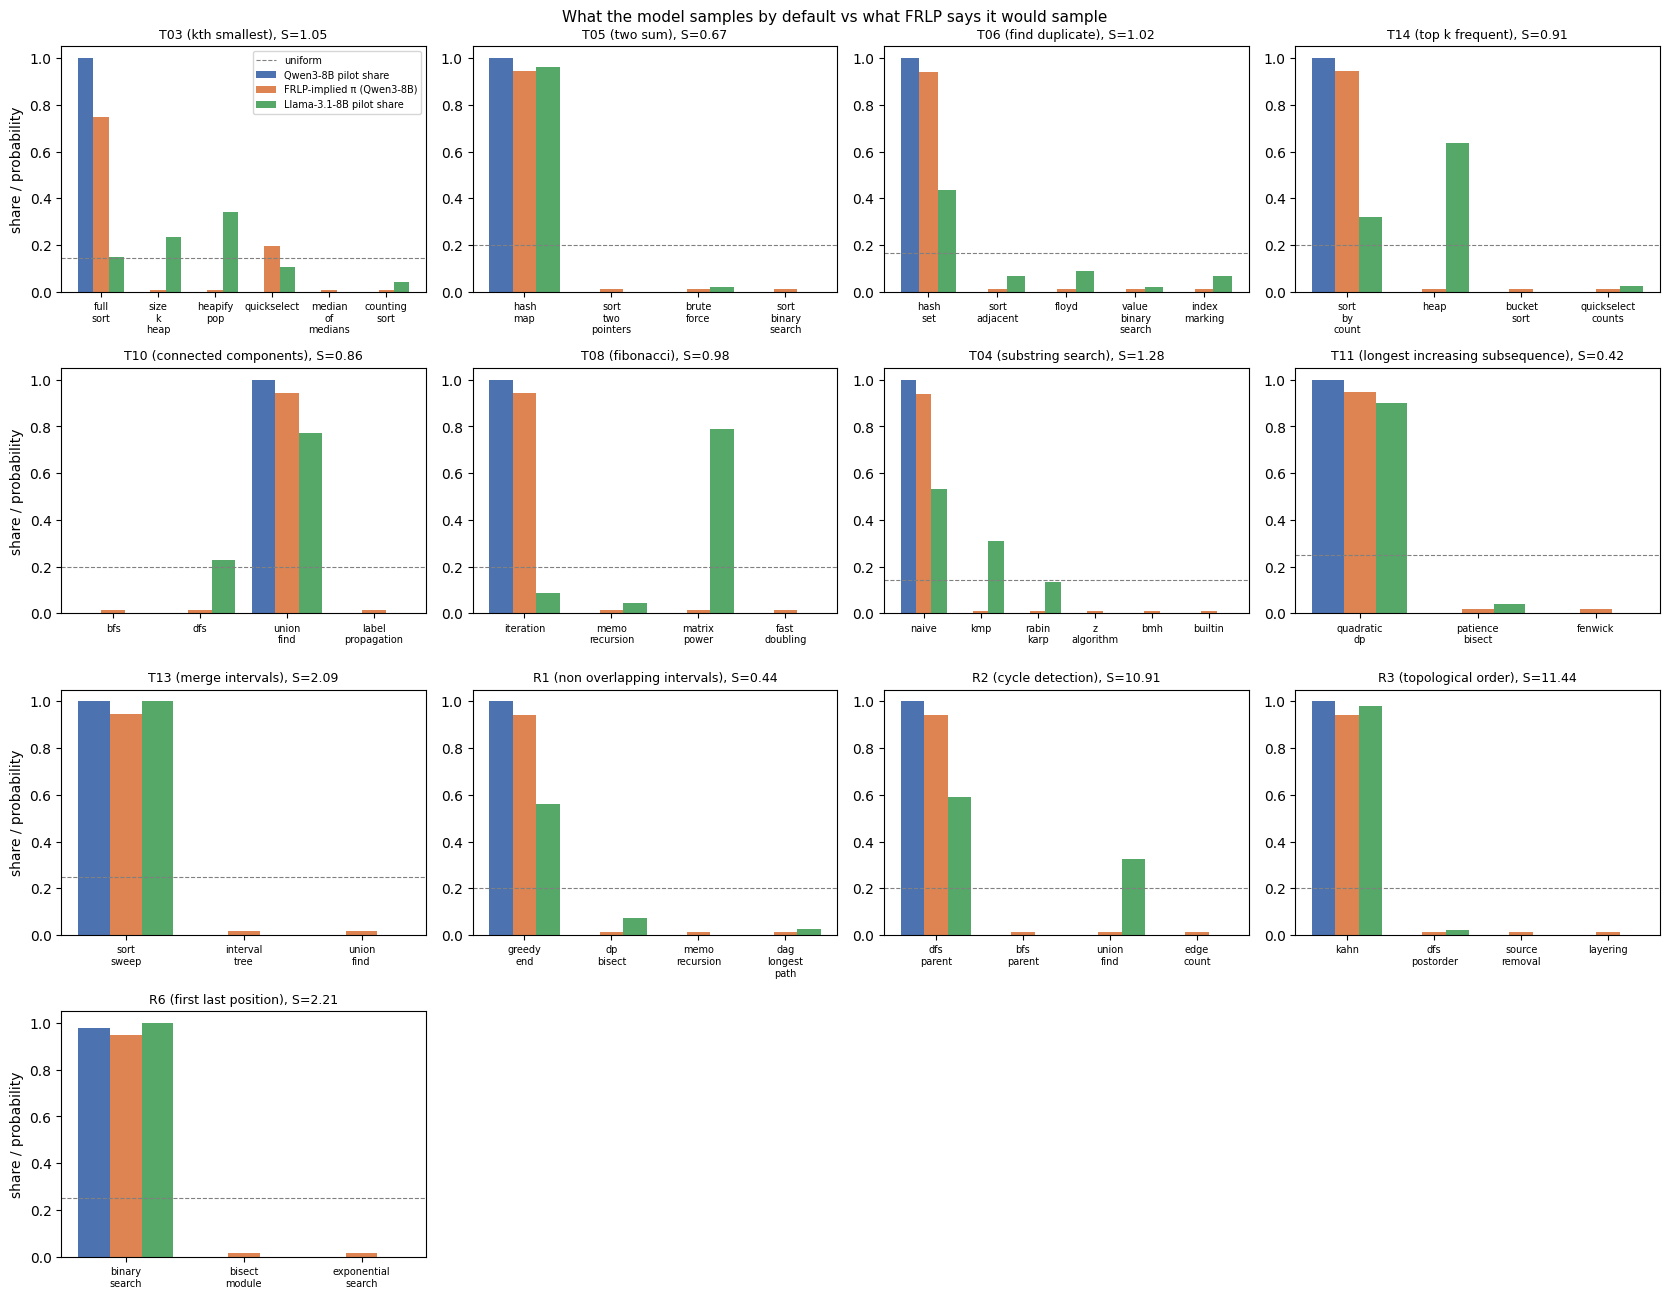

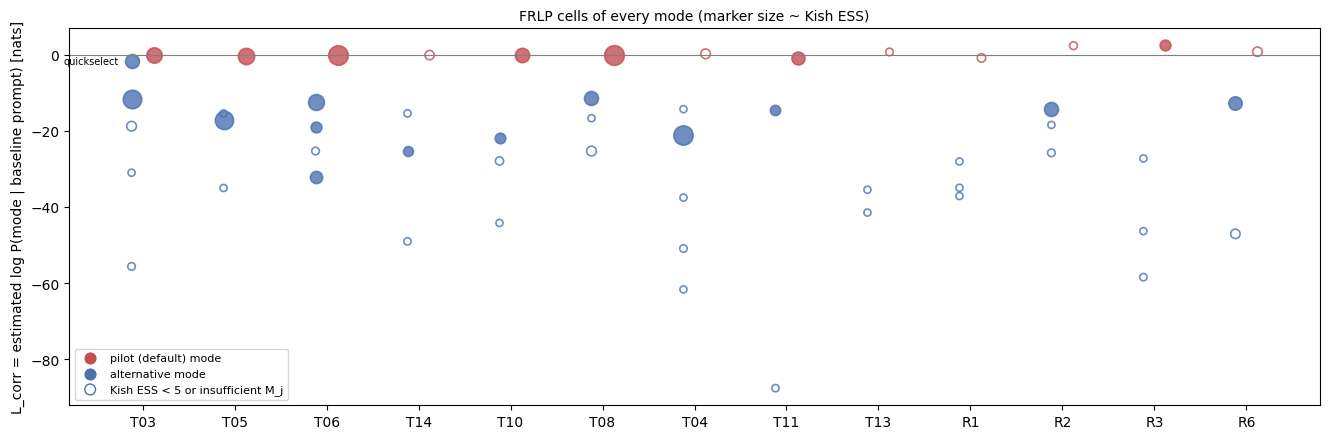

In [36]:
ncol = min(4, len(TASK_ORDER))
nrow = math.ceil(len(TASK_ORDER) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.3 * nrow), squeeze=False)
for ax, t in zip(axes.flat, TASK_ORDER):
    modes = list(TASKS[t]["modes"])
    s, v = stats[t], validity[t]
    qwen = [s["pilot_counts"].get(m, 0) / max(s["n_attempted"], 1) for m in modes]
    pi = [v["pi"].get(m, 0.0) for m in modes]
    lp = EXAMPLES[t]["original"]["llama_pilot_modal"] or {}
    lc = lp.get("pilot_counts") or {}
    n_l = sum(c for k, c in lc.items() if k != "invalid")
    llama = [lc.get(m, 0) / max(n_l, 1) for m in modes]
    x = np.arange(len(modes))
    ax.bar(x - 0.27, qwen, 0.27, label="Qwen3-8B pilot share", color="#4C72B0")
    ax.bar(x, pi, 0.27, label="FRLP-implied π (Qwen3-8B)", color="#DD8452")
    ax.bar(x + 0.27, llama, 0.27, label="Llama-3.1-8B pilot share", color="#55A868")
    ax.axhline(1 / (len(modes) + 1), color="grey", lw=0.8, ls="--", label="uniform")
    ax.set_xticks(x, [m.replace("_", "\n") for m in modes], fontsize=7)
    ax.set_ylim(0, 1.05)
    if ax in axes[:, 0]:
        ax.set_ylabel("share / probability")
    ax.set_title(f"{t} ({TASKS[t]['task_id'].split('_', 1)[1].replace('_', ' ')}), S={v['S']:.2f}", fontsize=9)
for ax in list(axes.flat)[len(TASK_ORDER):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=7, loc="upper right")
fig.suptitle("What the model samples by default vs what FRLP says it would sample", fontsize=11)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(max(6, 0.8 * len(TASK_ORDER) + 3), 4.5))
for xi, t in enumerate(TASK_ORDER):
    main = [c for c in cells if c["task"] == t and c["half"] == "all" and c["variant"] == "main" and c["L_corr"] is not None]
    for c in main:
        is_modal = c["algorithm"] == stats[t]["modal_label"]
        low = "ess_lt_5" in c["flags"] or "insufficient" in c["flags"]
        ax.scatter(xi + (0.12 if is_modal else -0.12), c["L_corr"], s=20 + 6 * c["ess"],
                   facecolors="none" if low else ("#C44E52" if is_modal else "#4C72B0"),
                   edgecolors="#C44E52" if is_modal else "#4C72B0", linewidths=1.2, alpha=0.8)
        if not is_modal and c["L_corr"] > -4:
            ax.annotate(c["algorithm"], (xi - 0.12, c["L_corr"]), fontsize=7, xytext=(-9, 0),
                        textcoords="offset points", ha="right", va="center")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(-0.8, len(TASK_ORDER) - 0.2)
ax.set_xticks(range(len(TASK_ORDER)), TASK_ORDER)
ax.set_ylabel("L_corr = estimated log P(mode | baseline prompt) [nats]")
ax.legend(handles=[plt.scatter([], [], s=60, color="#C44E52", label="pilot (default) mode"),
                   plt.scatter([], [], s=60, color="#4C72B0", label="alternative mode"),
                   plt.scatter([], [], s=60, facecolors="none", edgecolors="#4C72B0", label="Kish ESS < 5 or insufficient M_j")],
          fontsize=8, loc="lower left")
ax.set_title("FRLP cells of every mode (marker size ~ Kish ESS)", fontsize=10)
fig.tight_layout()
plt.show()

### What the numbers say (all 13 tasks, the default configuration)

- **Qwen3-8B is fully collapsed.** Its baseline pilot writes the same algorithm in 50/50 samples on 12 tasks, and in 49/50 on R6 (Wilson 95 % [0.929, 1.0]). No second mode reaches 10 %.
- **Collapse is model-specific.** Llama-3.1-8B, with the same specs and decoding, spreads over several modes on many tasks. On T03 its modal share is 0.34.
- **FRLP agrees with the pilot.** `argmax π` equals the pilot mode on 13/13 tasks, and π scores the pilot labels far better than uniform on every task.
- **FRLP still finds latent mass the pilot never shows.** The clearest case is T03 quickselect: `L_corr = -1.5`, about 0.21 of the probability mass, with 0/50 pilot samples. Most other alternatives have `L_corr` between -10 and -60 nats, where the pilot modes sit near 0.
- **S is in [0.3, 3] on 11/13 tasks.** R2 and R3 overshoot because their default-mode cells exceed 0 nats, an importance-sampling overestimate under low ESS.
- **ESS is low on many cells.** 34 of the 54 cells have Kish ESS < 5 (the hollow markers in the second figure).
- **The nominators disagree.** Free-form association, canonical-token proximity and the (fully tied) ladder name different successors for most modal events.
- **Stage B moves the order.** Breaking ladder ties with FRLP and using forced-program proximity gives Kendall τ = 0.54 against Stage A.
- **The re-run reproduces the original.** Every CPU-side number above is recomputed from the shipped data and matches the original run, apart from the documented R6 test truncation in the freeze hashes.